# مرحله سوم: آماده‌سازی داده‌ها (Data Preparation)

## پروژه Online Retail — از داده خام تا دیتاست‌های آماده تحلیل

در دو مرحله قبل (Business Understanding و Data Understanding) مشخص شد داده چه مشکلاتی دارد. در این مرحله **همان مشکلات با تصمیم‌های مشخص و قابل ردیابی مدیریت می‌شوند**، تا خروجی نهایی مستقیماً در خدمت چهار هدف پروژه باشد:

1. بخش‌بندی مشتریان بر اساس رفتار خرید (Customer Segmentation)
2. بررسی ارزش اقتصادی مشتریان و فرصت‌های بازاریابی (Customer Economic Value & Marketing Opportunity)
3. استخراج الگوهای خرید محصولات (Association Rule Mining)
4. انتخاب ۵۰۰ مشتری مناسب برای کمپین بازاریابی

**اصول حاکم بر این نوت‌بوک**

- داده خام هرگز تغییر نمی‌کند؛ همه کارها روی نسخه کاری انجام می‌شود.
- هیچ ردیفی بی‌صدا حذف نمی‌شود؛ هر ردیف یا برچسب نوع تراکنش می‌گیرد یا در یک فایل جداگانه ثبت می‌شود.
- تحلیل اکتشافی تکرار نمی‌شود؛ RFM اکتشافی مرحله قبل با نسخه نهایی و بر پایه «خرید معتبر» جایگزین می‌شود.
- مقادیر پرت حذف نمی‌شوند؛ فقط پرچم‌گذاری می‌شوند.
- ردیف‌های بدون CustomerID از تحلیل مشتری کنار گذاشته می‌شوند، اما برای تحلیل سبد خرید (ARM) نگه داشته می‌شوند.

## نقشه مراحل و خروجی‌ها

مراحل پاک‌سازی و ساخت ویژگی‌ها مانند قبل انجام می‌شوند؛ فقط در انتهای کار خروجی‌ها در **دو فایل نهایی** تجمیع می‌شوند:

| فایل نهایی | سطح هر ردیف | کاربرد |
|---|---|---|
| `customer_analysis.csv` | یک ردیف برای هر مشتری | RFM، ویژگی‌های رفتاری و اقتصادی، ورودی Segmentation و انتخاب ۵۰۰ مشتری |
| `product_basket.csv.gz` | یک ردیف برای هر فاکتور و یک ستون برای هر محصول | Association Rule Mining |

دیتافریم‌های میانی در طول اجرای نوت‌بوک برای پاک‌سازی، کنترل کیفیت و محاسبات حفظ می‌شوند؛ اما به‌صورت فایل‌های جداگانه خروجی گرفته نمی‌شوند. پارامترهای Scaling و گزارش کنترل‌ها نیز در نوت‌بوک باقی می‌مانند.

## تنظیمات و پارامترهای تصمیم‌گیری

همه تصمیم‌های قابل تنظیم در یک سلول جمع شده‌اند تا اگر لازم شد، با تغییر یک مقدار بتوان کل مسیر را دوباره اجرا کرد.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# ------------------------- پارامترهای تصمیم‌گیری -------------------------
RAW_PATH_CANDIDATES = ["Online Retail.csv", "Online Retail.xlsx", "Online_Retail.csv", "data/Online Retail.csv"]
OUTPUT_DIR = "prepared_data"

DROP_EXACT_DUPLICATES = True        # حذف ردیف‌های کاملاً تکراری (با ثبت در duplicates_removed)
KEEP_SINGLE_ITEM_BASKETS = False    # سبدهای تک‌محصولی در ماتریس ARM
MIN_ITEM_SUPPORT_FOR_MATRIX = 0.005 # حداقل Support (0.5٪) برای ورود محصول به basket_matrix
TREND_WINDOW_DAYS = 90              # طول پنجره‌های اخیر/قبلی برای شاخص روند خرید
MIN_PURCHASE_DAYS_INTERPURCHASE = 2 # حداقل روزهای خرید برای فاصله بین خریدها
SKEW_THRESHOLD = 1.0                # چولگی بالاتر از این مقدار => log1p
CORR_DROP_THRESHOLD = 0.85          # همبستگی بالاتر => حذف ویژگی تکراری از خوشه‌بندی
IQR_K_MILD, IQR_K_EXTREME = 1.5, 3.0

# کدهای غیرمحصولی (هزینه، خدمت، تعدیل)؛ بر پایه Data Understanding + بررسی دیتا در این مرحله
NON_PRODUCT_CODES = {"POST", "DOT", "M", "D", "C2", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK"}
NON_PRODUCT_DESC_REGEX = r"AMAZON FEE|POSTAGE|BANK CHARGE|^(NEXT DAY )?CARRIAGE$|^MANUAL$|ADJUST BAD DEBT|CRUK COMMISSION|^SAMPLES$|^DISCOUNT$"

os.makedirs(OUTPUT_DIR, exist_ok=True)
facts = {}            # مقادیر کلیدی برای گزارش‌دهی در مارک‌داون‌ها
flow_log = []         # ثبت تعداد رکوردها در هر مرحله
def log_flow(step, description, rows): flow_log.append({"Step": step, "Description": description, "Rows": int(rows)})

---
# مرحله 1: ایجاد نسخه کاری (Working Copy)

**هدف:** داده اصلی دست‌نخورده بماند و تمام تغییرات روی یک نسخه مستقل انجام شود.

**نکته فنی:** فایل `Online Retail.csv` داخل زیپ در عمل یک فایل **Excel (xlsx)** با پسوند csv است. لودر زیر نوع فایل را از روی امضای باینری تشخیص می‌دهد و هر دو حالت (CSV واقعی و Excel) را پشتیبانی می‌کند؛ بنابراین نیازی به تغییر دستی فایل نیست.

In [2]:
def load_raw(candidates):
    for path in candidates:
        if not os.path.exists(path):
            continue
        with open(path, "rb") as f:
            signature = f.read(2)
        if signature == b"PK":                       # فایل xlsx (zip-based)
            return pd.read_excel(path, engine="openpyxl"), path, "xlsx"
        for enc in ("utf-8", "latin-1"):
            try:
                return pd.read_csv(path, encoding=enc), path, f"csv ({enc})"
            except UnicodeDecodeError:
                continue
    raise FileNotFoundError(f"فایل داده در هیچ‌یک از مسیرها پیدا نشد: {candidates}")

raw_df, source_path, source_kind = load_raw(RAW_PATH_CANDIDATES)
retail_df = raw_df.copy(deep=True)       # نسخه کاری؛ raw_df تا پایان نوت‌بوک دست نمی‌خورد

print(f"Source: {source_path}  [{source_kind}]")
print("Shape:", retail_df.shape)
display(pd.DataFrame({"dtype": retail_df.dtypes.astype(str), "non_null": retail_df.notna().sum(), "nulls": retail_df.isna().sum()}))

facts["raw_rows"], facts["raw_cols"] = retail_df.shape
facts["raw_invoices"] = retail_df["InvoiceNo"].nunique()
facts["raw_products"] = retail_df["StockCode"].nunique()
facts["raw_customers"] = retail_df["CustomerID"].nunique()
log_flow("1", "Raw rows (working copy)", len(retail_df))

FileNotFoundError: فایل داده در هیچ‌یک از مسیرها پیدا نشد: ['Online Retail.csv', 'Online Retail.xlsx', 'Online_Retail.csv', 'data/Online Retail.csv']

### نتیجه مرحله 1

نسخه کاری `retail_df` با **541,909 ردیف و 8 ستون** ساخته شد. در داده خام **25,900 شماره فاکتور**، **4,070 StockCode** و **4,372 CustomerID یکتا** وجود دارد. این تعداد رکورد، مبنای مقایسه «قبل و بعد» در کل مرحله است.

---
# مرحله 2: پاک‌سازی و استانداردسازی (Data Cleaning)

**هدف:** یکسان‌سازی ساختار داده و رفع خطاهای فنی، بدون حذف داده‌های معنادار.

**تصمیم‌ها**

| موضوع | تصمیم | علت |
|---|---|---|
| InvoiceDate | تبدیل به datetime | تحلیل زمانی و Recency |
| CustomerID | تبدیل به **رشته** (مثلاً `"17850"`) و حفظ مقادیر گمشده | شناسه است، نه ویژگی عددی؛ و مقدار ساختگی برای گمشده‌ها ساخته نمی‌شود |
| InvoiceNo / StockCode | حذف فاصله و یکدست‌سازی حروف بزرگ | جلوگیری از کدهای تکراریِ ظاهری |
| Description | حذف فاصله اضافی و حروف بزرگ | یکدست‌سازی نام محصول |
| Quantity / UnitPrice | فقط کنترل نوع و مقادیر غیرمنطقی؛ **حذف نمی‌شوند** | مقادیر منفی/صفر در مرحله 3 تفسیر می‌شوند |
| ردیف‌های کاملاً تکراری | قاعده‌مند مدیریت می‌شوند (پایین‌تر) | اثر مالی و ساختاری باید قبل از حذف سنجیده شود |

In [ ]:
retail_cleaned = retail_df.copy(deep=True)
retail_cleaned.insert(0, "SourceRow", retail_cleaned.index)      # کلید ردیابی به داده خام

# --- تاریخ ---
if not pd.api.types.is_datetime64_any_dtype(retail_cleaned["InvoiceDate"]):
    parsed = pd.to_datetime(retail_cleaned["InvoiceDate"], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.01:
        parsed = pd.to_datetime(retail_cleaned["InvoiceDate"], errors="coerce")
    retail_cleaned["InvoiceDate"] = parsed

# --- شناسه‌ها ---
retail_cleaned["InvoiceNo"] = retail_cleaned["InvoiceNo"].astype("string").str.strip().str.upper()
retail_cleaned["StockCode"] = retail_cleaned["StockCode"].astype("string").str.strip().str.upper()
retail_cleaned["CustomerID"] = (
    pd.to_numeric(retail_cleaned["CustomerID"], errors="coerce").astype("Int64").astype("string")
)

# --- متن‌ها ---
retail_cleaned["Description"] = (
    retail_cleaned["Description"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip().str.upper()
)
retail_cleaned["Country"] = retail_cleaned["Country"].astype("string").str.strip()

# --- کنترل نوع عددی ---
retail_cleaned["Quantity"] = pd.to_numeric(retail_cleaned["Quantity"], errors="coerce")
retail_cleaned["UnitPrice"] = pd.to_numeric(retail_cleaned["UnitPrice"], errors="coerce")

# --- گزارش کیفیت ---
quality = pd.DataFrame({
    "dtype": retail_cleaned.dtypes.astype(str),
    "missing": retail_cleaned.isna().sum(),
    "missing_%": retail_cleaned.isna().mean() * 100,
})
display(quality)

facts["miss_customer"] = int(retail_cleaned["CustomerID"].isna().sum())
facts["miss_customer_pct"] = float(retail_cleaned["CustomerID"].isna().mean() * 100)
facts["miss_desc"] = int(retail_cleaned["Description"].isna().sum())
facts["bad_dates"] = int(retail_cleaned["InvoiceDate"].isna().sum())
facts["date_min"] = str(retail_cleaned["InvoiceDate"].min())
facts["date_max"] = str(retail_cleaned["InvoiceDate"].max())
print("Invalid dates:", facts["bad_dates"], "| Date range:", facts["date_min"], "→", facts["date_max"])
print("Missing Quantity/UnitPrice:", int(retail_cleaned["Quantity"].isna().sum()), int(retail_cleaned["UnitPrice"].isna().sum()))

,dtype,missing,missing_%
SourceRow,int64,0,0.00
InvoiceNo,string,0,0.00
StockCode,string,0,0.00
Description,string,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
UnitPrice,float64,0,0.00
CustomerID,string,135080,24.93
Country,string,0,0.00


Invalid dates: 0 | Date range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Missing Quantity/UnitPrice: 0 0


### رکوردهای تکراری: اندازه‌گیری اثر قبل از تصمیم

تکرار یک ردیف لزوماً خطا نیست. بنابراین اول **اثر حذف** روی Quantity، مبلغ، تعداد فاکتور و سبد محصولی سنجیده می‌شود.

In [ ]:
dup_cols = [c for c in retail_cleaned.columns if c != "SourceRow"]
dup_mask = retail_cleaned.duplicated(subset=dup_cols, keep="first")
line_amount = retail_cleaned["Quantity"] * retail_cleaned["UnitPrice"]

pairs_before = retail_cleaned[["InvoiceNo", "StockCode"]].drop_duplicates().shape[0]
pairs_after = retail_cleaned.loc[~dup_mask, ["InvoiceNo", "StockCode"]].drop_duplicates().shape[0]
inv_before, inv_after = retail_cleaned["InvoiceNo"].nunique(), retail_cleaned.loc[~dup_mask, "InvoiceNo"].nunique()

dup_impact = pd.DataFrame({
    "Metric": ["Duplicate rows (excluding first occurrence)", "…of which with CustomerID",
               "Quantity affected", "Line amount affected (GBP)",
               "Unique invoices before → after", "Unique (invoice, product) pairs before → after"],
    "Value": [int(dup_mask.sum()), int(retail_cleaned.loc[dup_mask, "CustomerID"].notna().sum()),
              f"{retail_cleaned.loc[dup_mask, 'Quantity'].sum():,.0f}", f"{line_amount[dup_mask].sum():,.2f}",
              f"{inv_before:,} → {inv_after:,}", f"{pairs_before:,} → {pairs_after:,}"]
})
display(dup_impact)

same_minute_share = (retail_cleaned.loc[dup_mask, "InvoiceDate"].notna()).mean() * 100
facts["dup_rows"] = int(dup_mask.sum())
facts["dup_with_customer"] = int(retail_cleaned.loc[dup_mask, "CustomerID"].notna().sum())
facts["dup_amount"] = float(line_amount[dup_mask].sum())
facts["dup_invoices_lost"] = int(inv_before - inv_after)
facts["dup_pairs_lost"] = int(pairs_before - pairs_after)

# --- تصمیم ---
retail_cleaned["IsExactDuplicate"] = dup_mask.values
if DROP_EXACT_DUPLICATES:
    duplicates_removed = retail_cleaned[dup_mask].copy()
    retail_cleaned = retail_cleaned[~dup_mask].drop(columns="IsExactDuplicate").reset_index(drop=True)
else:
    duplicates_removed = retail_cleaned.iloc[0:0].copy()
    retail_cleaned = retail_cleaned.drop(columns="IsExactDuplicate")

log_flow("2", "Exact duplicate rows removed (saved in duplicates_removed)", len(duplicates_removed))
log_flow("2", "retail_cleaned rows", len(retail_cleaned))
print("retail_cleaned:", retail_cleaned.shape, "| duplicates_removed:", duplicates_removed.shape)

,Metric,Value
0,Duplicate rows (excluding first occurrence),5268
1,…of which with CustomerID,5225
2,Quantity affected,"13,948"
3,Line amount affected (GBP),"21,740.98"
4,Unique invoices before → after,"25,900 → 25,900"
5,"Unique (invoice, product) pairs before → after","531,223 → 531,223"


retail_cleaned: (536641, 9) | duplicates_removed: (5268, 10)


### نتیجه مرحله 2

- **135,080 ردیف (24.93٪)** CustomerID ندارند و **1,454 ردیف** Description ندارند. هیچ‌کدام حذف یا با مقدار ساختگی پر نشدند.
- تاریخ‌ها بدون خطا تبدیل شدند (**0** مقدار نامعتبر) و بازه داده از `2010-12-01 08:26:00` تا `2011-12-09 12:50:00` است.
- **5,268 ردیف کاملاً تکراری** (که 5,225 تای آن‌ها CustomerID دارند) با مبلغ تجمیعی حدود **21,741 پوند** شناسایی شد.
- حذف تکراری‌ها **هیچ فاکتوری را از بین نمی‌برد** (0 فاکتور) و هیچ جفت «فاکتور–محصول» را حذف نمی‌کند (0 جفت)؛ یعنی Frequency و سبدهای ARM تحت تأثیر قرار نمی‌گیرند و فقط Quantity و Monetary از افزایش مصنوعی جلوگیری می‌شود.

**تصمیم:** ردیف‌های کاملاً تکراری از `retail_cleaned` کنار گذاشته شدند (نگه‌داری اولین رخداد). خود ردیف‌های حذف‌شده در `duplicates_removed` ثبت شده‌اند و با کلید `SourceRow` به داده خام وصل می‌شوند. برای رد این تصمیم کافی است `DROP_EXACT_DUPLICATES = False` شود.

---
# مرحله 3: مدیریت لغو سفارش و مرجوعی (Cancellation & Returns Handling)

**هدف:** تفکیک خرید واقعی از لغو، مرجوعی، تعدیل موجودی و اقلام غیرمحصولی؛ بدون حذف بی‌ثبت.

بر اساس Data Understanding، هر ردیف دقیقاً یک **نوع تراکنش (`TransactionType`)** می‌گیرد. ترتیب قواعد مهم است (اولین قاعده‌ای که برقرار باشد برنده است):

| ترتیب | نوع تراکنش | شرط |
|---|---|---|
| 1 | `Cancellation` | شماره فاکتور با `C` شروع شود |
| 2 | `Non-Product / Fee` | کد/توضیح غیرمحصولی (POST، DOT، M، D، C2، S، B، BANK CHARGES، AMAZONFEE، CRUK، GIFT_*) |
| 3 | `Inventory Adjustment` | فاکتور بدون C، Quantity منفی، قیمت صفر، بدون CustomerID |
| 4 | `Return Candidate (non-C)` | فاکتور بدون C، Quantity منفی، قیمت مثبت، دارای CustomerID |
| 5 | `Negative Qty - Review` | سایر Quantityهای منفی |
| 6 | `Zero Price - Review` | قیمت صفر (یا Quantity صفر) |
| 7 | `Negative Price - Review` | قیمت منفی |
| 8 | `Valid Product Purchase` | فاکتور بدون C، محصولی، Quantity > 0 و UnitPrice > 0 |

> کدهای `C2` (Carriage)، `S` (Samples) و `B` (Adjust bad debt) در بررسی داده این مرحله به فهرست اقلام غیرمحصولی Data Understanding اضافه شدند؛ چون هزینه حمل، نمونه و تعدیل حسابداری‌اند، نه کالای قابل فروش.

In [ ]:
sc, desc, inv = retail_cleaned["StockCode"], retail_cleaned["Description"], retail_cleaned["InvoiceNo"]

by_code = sc.isin(NON_PRODUCT_CODES) | sc.str.startswith("GIFT_", na=False)
by_desc = desc.str.contains(NON_PRODUCT_DESC_REGEX, na=False, regex=True)
retail_cleaned["IsNonProduct"] = (by_code | by_desc).astype(bool)
retail_cleaned["IsCancellationInvoice"] = inv.str.startswith("C", na=False).astype(bool)

# کنترل: ردیف‌هایی که فقط با توضیح غیرمحصولی شناسایی شده‌اند (نباید محصول واقعی باشند)
only_by_desc = retail_cleaned[by_desc & ~by_code]
print("Rows flagged only by description:", len(only_by_desc))
display(only_by_desc.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(10).to_frame("rows"))

q, p = retail_cleaned["Quantity"], retail_cleaned["UnitPrice"]
conditions = [
    retail_cleaned["IsCancellationInvoice"],
    retail_cleaned["IsNonProduct"],
    (q < 0) & (p == 0) & retail_cleaned["CustomerID"].isna(),
    (q < 0) & (p > 0) & retail_cleaned["CustomerID"].notna(),
    (q < 0),
    (p == 0) | (q == 0),
    (p < 0),
    (q > 0) & (p > 0),
]
labels = ["Cancellation", "Non-Product / Fee", "Inventory Adjustment", "Return Candidate (non-C)",
          "Negative Qty - Review", "Zero Price - Review", "Negative Price - Review", "Valid Product Purchase"]
retail_cleaned["TransactionType"] = np.select(conditions, labels, default="Other / Needs Investigation")
retail_cleaned["LineAmount"] = retail_cleaned["Quantity"] * retail_cleaned["UnitPrice"]

type_summary = (retail_cleaned.groupby("TransactionType")
                .agg(Rows=("SourceRow", "size"), Invoices=("InvoiceNo", "nunique"), Amount_GBP=("LineAmount", "sum"))
                .sort_values("Rows", ascending=False))
type_summary["Rows_%"] = type_summary["Rows"] / type_summary["Rows"].sum() * 100
display(type_summary)

for k, label in {"n_cancel": "Cancellation", "n_nonprod": "Non-Product / Fee", "n_invadj": "Inventory Adjustment",
                 "n_retcand": "Return Candidate (non-C)", "n_negrev": "Negative Qty - Review",
                 "n_zero": "Zero Price - Review", "n_negprice": "Negative Price - Review",
                 "n_valid_rows": "Valid Product Purchase"}.items():
    facts[k] = int((retail_cleaned["TransactionType"] == label).sum())
facts["n_other"] = int((retail_cleaned["TransactionType"] == "Other / Needs Investigation").sum())
facts["cancel_invoices"] = int(retail_cleaned.loc[retail_cleaned["TransactionType"] == "Cancellation", "InvoiceNo"].nunique())
facts["zero_price_with_cust"] = int(((retail_cleaned["TransactionType"] == "Zero Price - Review") & retail_cleaned["CustomerID"].notna()).sum())
facts["nonprod_in_noncancel"] = int(((retail_cleaned["TransactionType"] == "Non-Product / Fee")).sum())
assert facts["n_other"] == 0, "ردیفی بدون نوع مشخص باقی مانده است"

Rows flagged only by description: 81


,,rows
StockCode,Description,
23444,NEXT DAY CARRIAGE,80
21656,SAMPLES,1


,Rows,Invoices,Amount_GBP,Rows_%
TransactionType,,,,
Valid Product Purchase,522461,19773,"10,246,019.32",97.36
Cancellation,9251,3836,"-893,979.73",1.72
Non-Product / Fee,2437,2371,"373,967.36",0.45
Inventory Adjustment,1335,1335,0.00,0.25
Zero Price - Review,1157,804,0.00,0.22


### تطبیق لغوها با خرید قبلی (Cancellation Matching)

پیشوند `C` فقط می‌گوید فاکتور لغو/برگشت است؛ نمی‌گوید به کدام خرید مربوط است. برای تفکیک «لغو سریع/مرجوعی محتمل» از «لغو بدون سابقه»، هر ردیف لغوِ محصولی با **خریدهای قبلی همان مشتری و همان محصول** تطبیق داده می‌شود، به‌صورت ترتیب‌زمانی و با کسر لغوهای قبلی از موجودی قابل‌تطبیق (تا یک خرید دوبار مصرف نشود).

این تطبیق **شاهد کمکی** است، نه اثبات حقوقی/مالی.

In [ ]:
purch = retail_cleaned[(retail_cleaned["TransactionType"] == "Valid Product Purchase") & retail_cleaned["CustomerID"].notna()].copy()
purch["CS"] = purch["CustomerID"].astype(str) + "|" + purch["StockCode"].astype(str)
purch = purch.sort_values("InvoiceDate", kind="stable")
purch["PurchasedQtyCum"] = purch.groupby("CS")["Quantity"].cumsum()

canc = retail_cleaned[(retail_cleaned["TransactionType"] == "Cancellation") & (~retail_cleaned["IsNonProduct"])
                      & retail_cleaned["CustomerID"].notna()].copy()
canc["CS"] = canc["CustomerID"].astype(str) + "|" + canc["StockCode"].astype(str)
canc = canc.sort_values("InvoiceDate", kind="stable")
canc["AbsQty"] = -canc["Quantity"]
canc["CancelCumBefore"] = canc.groupby("CS")["AbsQty"].cumsum() - canc["AbsQty"]

matched = pd.merge_asof(
    canc[["SourceRow", "CS", "InvoiceDate", "AbsQty", "UnitPrice", "CancelCumBefore"]],
    purch[["CS", "InvoiceDate", "PurchasedQtyCum"]].rename(columns={"InvoiceDate": "PriorPurchaseDate"}),
    left_on="InvoiceDate", right_on="PriorPurchaseDate", by="CS", direction="backward"
)
matched["AvailableQty"] = (matched["PurchasedQtyCum"].fillna(0) - matched["CancelCumBefore"]).clip(lower=0)
matched["MatchedQty"] = np.minimum(matched["AbsQty"], matched["AvailableQty"])
matched["CancelStatus"] = np.select(
    [matched["MatchedQty"] <= 0, matched["MatchedQty"] >= matched["AbsQty"]],
    ["Unmatched - no prior purchase", "Matched - fully covered"],
    default="Matched - partially covered")
matched["CancelValue"] = matched["AbsQty"] * matched["UnitPrice"]
matched["MatchedCancelValue"] = matched["MatchedQty"] * matched["UnitPrice"]
match_info = matched[["SourceRow", "PriorPurchaseDate", "MatchedQty", "CancelStatus", "CancelValue", "MatchedCancelValue"]]

status_summary = match_info.groupby("CancelStatus").agg(Rows=("SourceRow", "size"), Value_GBP=("CancelValue", "sum"))
status_summary["Rows_%"] = status_summary["Rows"] / status_summary["Rows"].sum() * 100
display(status_summary)

facts["canc_prod_rows"] = len(match_info)
facts["canc_match_any_pct"] = float((match_info["MatchedQty"] > 0).mean() * 100)
facts["canc_full_pct"] = float((match_info["CancelStatus"] == "Matched - fully covered").mean() * 100)
facts["canc_no_customer"] = int(((retail_cleaned["TransactionType"] == "Cancellation") & retail_cleaned["CustomerID"].isna()).sum())
facts["canc_nonprod"] = int(((retail_cleaned["TransactionType"] == "Cancellation") & retail_cleaned["IsNonProduct"]).sum())

,Rows,Value_GBP,Rows_%
CancelStatus,,,
Matched - fully covered,7385,"446,056.41",86.83
Matched - partially covered,62,"2,889.04",0.73
Unmatched - no prior purchase,1058,"22,790.26",12.44


In [ ]:
# --- ساخت دیتاست‌های خروجی مرحله 3 ---
valid_purchases = retail_cleaned[retail_cleaned["TransactionType"] == "Valid Product Purchase"].copy()

return_types = ["Cancellation", "Inventory Adjustment", "Return Candidate (non-C)", "Negative Qty - Review"]
returns_cancellations = (retail_cleaned[retail_cleaned["TransactionType"].isin(return_types)]
                         .merge(match_info, on="SourceRow", how="left"))
fallback_status = pd.Series(
    np.where(returns_cancellations["TransactionType"] == "Cancellation",
             np.where(returns_cancellations["CustomerID"].isna(), "No CustomerID", "Non-product cancellation"),
             "Not applicable"),
    index=returns_cancellations.index)
returns_cancellations["CancelStatus"] = returns_cancellations["CancelStatus"].fillna(fallback_status)

# ردیف‌هایی که نه خرید معتبرند و نه لغو/مرجوعی (هزینه‌ها، قیمت صفر و ...)؛ برای ردیابی نگه داشته می‌شوند
excluded_other_rows = retail_cleaned[~retail_cleaned["TransactionType"].isin(return_types + ["Valid Product Purchase"])].copy()

print("valid_purchases:", valid_purchases.shape)
print("returns_cancellations:", returns_cancellations.shape)
print("excluded_other_rows:", excluded_other_rows.shape)
display(returns_cancellations.groupby(["TransactionType", "CancelStatus"]).size().to_frame("rows"))

log_flow("3", "valid_purchases (valid product purchase rows)", len(valid_purchases))
log_flow("3", "returns_cancellations", len(returns_cancellations))
log_flow("3", "excluded_other_rows (non-product, zero/negative price)", len(excluded_other_rows))
assert len(valid_purchases) + len(returns_cancellations) + len(excluded_other_rows) == len(retail_cleaned)

# مثال مشتری 12346 (لغو سریع سفارش در Data Understanding)
display(retail_cleaned.loc[retail_cleaned["CustomerID"] == "12346",
        ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "TransactionType"]])

valid_purchases: (522461, 13)
returns_cancellations: (10586, 18)
excluded_other_rows: (3594, 13)


rows
TransactionType      CancelStatus                       
Cancellation         Matched - fully covered        7385
                     Matched - partially covered      62
                     No CustomerID                   379
                     Non-product cancellation        367
                     Unmatched - no prior purchase  1058
Inventory Adjustment Not applicable                 1335

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,TransactionType
61006,541431,23166,74215,2011-01-18 10:01:00,1.04,Valid Product Purchase
61011,C541433,23166,-74215,2011-01-18 10:17:00,1.04,Cancellation


### نتیجه مرحله 3

- از **541,909** ردیف خام، پس از حذف تکراری‌ها **522,461 ردیف** «خرید معتبر محصولی» هستند؛ بقیه برچسب مشخص گرفتند و هیچ ردیفی بی‌نوع نماند (**0** ردیف Other).
- **9,251 ردیف** در **3,836 فاکتور لغوشده** (پیشوند C) قرار دارند. از این تعداد **8,505 ردیف** محصولی و دارای CustomerID‌اند و **379 ردیف** CustomerID ندارند (به مشتری قابل نسبت دادن نیستند) و **584 ردیف** لغوِ اقلام غیرمحصولی‌اند.
- **87.6٪** لغوهای محصولی با خرید قبلیِ همان مشتری و محصول تطبیق دارند و **86.8٪** آن‌ها کاملاً توسط خریدهای قبلی پوشش داده می‌شوند؛ این شاهد می‌گوید بخش اصلی لغوها در واقع برگشت/اصلاح خرید قبلی است، نه سفارش بی‌سابقه.
- **1,335 ردیف** Quantity منفی بدون C، با قیمت صفر و بدون CustomerID دارند؛ با توضیحاتی مثل check/damaged/found، این‌ها **تعدیل موجودی** هستند و نه مرجوعی مشتری. ردیف «مرجوعی غیر-C با قیمت مثبت» در این داده **0** مورد است.
- **2,437 ردیف** غیرمحصولی (حمل، تخفیف، هزینه Amazon، بانک، Manual و ...) و **1,157 ردیف** با قیمت صفر (34 تای آن‌ها دارای CustomerID) و **0 ردیف** با قیمت منفی از فروش کنار گذاشته شدند، اما در `excluded_other_rows` نگه‌داری می‌شوند.
- مثال مشتری ۱۲۳۴۶: یک خرید بسیار بزرگ دارد که حدود ۱۶ دقیقه بعد کامل لغو شده است. این الگو در Monetary ناخالص دیده می‌شود، بنابراین در مراحل بعد **شاخص مرجوعی و Net Monetary** جداگانه محاسبه می‌شود.

**خروجی‌ها:** `valid_purchases`، `returns_cancellations`، و `excluded_other_rows` (برای ردیابی کامل).

---
# مرحله 4: مدیریت مقادیر پرت (Outlier Treatment)

**هدف:** شناسایی مقادیر غیرعادی و تصمیم درباره نحوه استفاده از آن‌ها، **بدون حذف خودکار**.

رویکرد:
1. روی خریدهای معتبر، مقدار پرت با IQR در دو سطح **ملایم (1.5×IQR)** و **شدید (3×IQR)** علامت‌گذاری می‌شود.
2. مقادیر پرت در سه سطح **ردیف، فاکتور و مشتری** بررسی می‌شوند (سطح مشتری بعد از ساخت ویژگی‌ها در مرحله 6).
3. موارد حدی به‌صورت موردی بررسی می‌شوند، مخصوصاً اینکه آیا بعداً لغو شده‌اند.
4. تصمیم: **نگه‌داری + پرچم**؛ و برای خوشه‌بندی فقط تبدیل لگاریتمی/Scaling روی نسخه جدا (مرحله 8).

,Feature,Median,P99,Max,Mild bound,Extreme bound,Mild outliers,Mild %,Extreme outliers
0,Quantity,4.00,100.00,"80,995.00",28.50,45.00,26815,5.13,19152
1,UnitPrice,2.08,16.63,649.50,8.45,12.77,35670,6.83,10047
2,LineAmount,9.90,179.00,"168,469.60",38.40,59.10,41120,7.87,26237


Invoice value: median=302  mean=518  max=168,470
Mild outlier invoices (> 976): 1802  → 47.2% of total valid value
Extreme outlier invoices (> 1,471): 1021


,InvoiceNo,CustomerID,Country,StockCode,Description,Quantity,UnitPrice,LineAmount,CancelledQty_sameCustomerProduct
520994,581483,16446,United Kingdom,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60","80,995.00"
59407,541431,12346,United Kingdom,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60","74,215.00"
214404,556444,15098,United Kingdom,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",60.00
335835,567423,17450,United Kingdom,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72",0.00
50697,540815,15749,United Kingdom,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40","3,114.00"
154453,550461,15749,United Kingdom,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40","3,114.00"
406224,573003,14646,Netherlands,23084,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00",0.00
50695,540815,15749,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50","1,930.00"
450860,576365,<NA>,United Kingdom,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,"4,781.60",0.00
154449,550461,15749,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,"4,632.00","1,930.00"


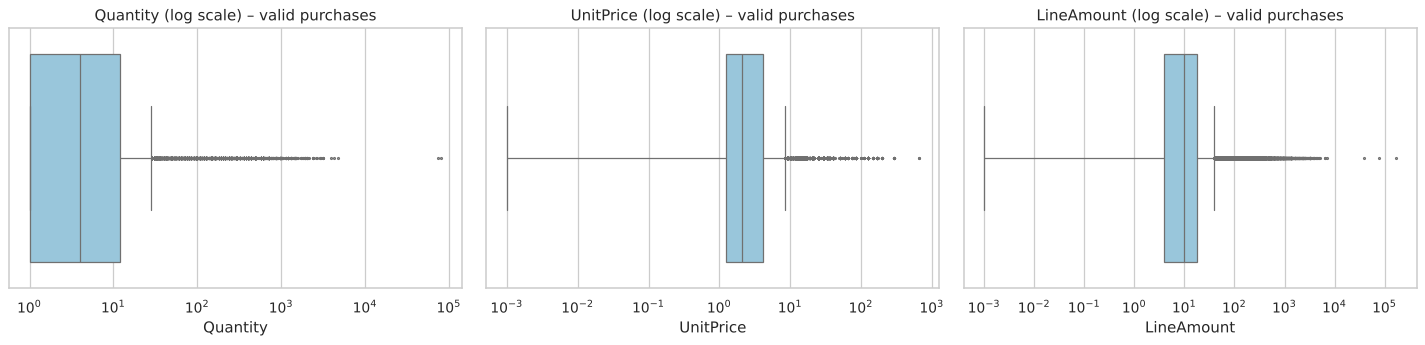

In [ ]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# ---------- سطح ردیف ----------
row_report = []
for col in ["Quantity", "UnitPrice", "LineAmount"]:
    _, hi_m = iqr_bounds(valid_purchases[col], IQR_K_MILD)
    _, hi_e = iqr_bounds(valid_purchases[col], IQR_K_EXTREME)
    valid_purchases[f"Out_{col}"] = valid_purchases[col] > hi_m
    valid_purchases[f"OutExt_{col}"] = valid_purchases[col] > hi_e
    row_report.append({"Feature": col, "Median": valid_purchases[col].median(), "P99": valid_purchases[col].quantile(.99),
                       "Max": valid_purchases[col].max(), "Mild bound": hi_m, "Extreme bound": hi_e,
                       "Mild outliers": int(valid_purchases[f"Out_{col}"].sum()),
                       "Mild %": valid_purchases[f"Out_{col}"].mean() * 100,
                       "Extreme outliers": int(valid_purchases[f"OutExt_{col}"].sum())})
display(pd.DataFrame(row_report))

# ---------- سطح فاکتور ----------
invoice_summary = (valid_purchases.groupby("InvoiceNo")
    .agg(CustomerID=("CustomerID", "first"), Country=("Country", "first"), InvoiceDate=("InvoiceDate", "min"),
         InvoiceValue=("LineAmount", "sum"), InvoiceQuantity=("Quantity", "sum"), DistinctProducts=("StockCode", "nunique"))
    .reset_index())
_, inv_hi_m = iqr_bounds(invoice_summary["InvoiceValue"], IQR_K_MILD)
_, inv_hi_e = iqr_bounds(invoice_summary["InvoiceValue"], IQR_K_EXTREME)
invoice_summary["Out_InvoiceValue"] = invoice_summary["InvoiceValue"] > inv_hi_m
invoice_summary["OutExt_InvoiceValue"] = invoice_summary["InvoiceValue"] > inv_hi_e
valid_purchases = valid_purchases.merge(invoice_summary[["InvoiceNo", "Out_InvoiceValue", "OutExt_InvoiceValue"]],
                                        on="InvoiceNo", how="left")

share_val = invoice_summary.loc[invoice_summary["Out_InvoiceValue"], "InvoiceValue"].sum() / invoice_summary["InvoiceValue"].sum() * 100
print(f"Invoice value: median={invoice_summary['InvoiceValue'].median():,.0f}  mean={invoice_summary['InvoiceValue'].mean():,.0f}  max={invoice_summary['InvoiceValue'].max():,.0f}")
print(f"Mild outlier invoices (> {inv_hi_m:,.0f}): {int(invoice_summary['Out_InvoiceValue'].sum())}  → {share_val:.1f}% of total valid value")
print(f"Extreme outlier invoices (> {inv_hi_e:,.0f}): {int(invoice_summary['OutExt_InvoiceValue'].sum())}")

facts["inv_median"] = float(invoice_summary["InvoiceValue"].median())
facts["inv_mean"] = float(invoice_summary["InvoiceValue"].mean())
facts["inv_max"] = float(invoice_summary["InvoiceValue"].max())
facts["inv_out_mild"] = int(invoice_summary["Out_InvoiceValue"].sum())
facts["inv_out_ext"] = int(invoice_summary["OutExt_InvoiceValue"].sum())
facts["inv_out_share"] = float(share_val)
facts["valid_invoice_count"] = len(invoice_summary)
facts["qty_out_rows"] = int(valid_purchases["Out_Quantity"].sum())
facts["qty_out_pct"] = float(valid_purchases["Out_Quantity"].mean() * 100)

# ---------- بررسی موردی ۱۰ ردیف بزرگ: آیا بعداً لغو شده‌اند؟ ----------
cancelled_by_pair = (canc.groupby("CS")["AbsQty"].sum().rename("CancelledQty_sameCustomerProduct"))
top_rows = valid_purchases.assign(CS=valid_purchases["CustomerID"].astype(str) + "|" + valid_purchases["StockCode"].astype(str)) \
    .nlargest(10, "LineAmount") \
    .merge(cancelled_by_pair, left_on="CS", right_index=True, how="left")
top_rows["CancelledQty_sameCustomerProduct"] = top_rows["CancelledQty_sameCustomerProduct"].fillna(0)
display(top_rows[["InvoiceNo", "CustomerID", "Country", "StockCode", "Description", "Quantity", "UnitPrice",
                  "LineAmount", "CancelledQty_sameCustomerProduct"]])
facts["top_rows_fully_cancelled"] = int((top_rows["CancelledQty_sameCustomerProduct"] >= top_rows["Quantity"]).sum())

# ---------- نمودار ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "LineAmount"]):
    sns.boxplot(x=valid_purchases[col], ax=ax, color="#8ecae6", fliersize=1.5)
    ax.set_xscale("log"); ax.set_title(f"{col} (log scale) – valid purchases")
plt.tight_layout(); plt.show()

### نتیجه مرحله 4

- روی **ردیف‌ها**، 26,815 ردیف (5.1٪) از نظر Quantity با IQR ملایم پرت‌اند. این نسبت بالا طبیعی است؛ چون فروشگاه عمده‌فروش دارد و توزیع شدیداً راست‌چوله است، پس IQR روی ردیف خام قاعده‌ای برای **حذف** نیست.
- روی **فاکتورها**، میانه ارزش فاکتور حدود **302 پوند**، میانگین **518** و بیشینه **168,470** پوند است. **1,802 فاکتور** (از 19,773) پرت ملایم و **1,021 فاکتور** پرت شدید محسوب می‌شوند و مجموعاً **47.2٪** از ارزش خرید معتبر را می‌سازند.
- در بررسی موردی ۱۰ ردیف بزرگ، **7 مورد** بعداً توسط همان مشتری برای همان محصول به‌طور کامل لغو شده‌اند. پس بزرگ بودن به‌تنهایی نه «خطا» است و نه «ارزش واقعی»؛ باید با شاخص مرجوعی/Net Monetary سنجیده شود.

**تصمیم:** هیچ مقدار پرتی حذف نشد. پرچم‌های `Out_*` و `OutExt_*` به `valid_purchases` اضافه شد. برای خوشه‌بندی، اثر مقادیر پرت با تبدیل لگاریتمی و Scaling در مرحله 8 کنترل می‌شود، بدون تغییر در داده اصلی.

---
# مرحله 5: ساخت دیتاست خرید معتبر (Valid Transaction Dataset)

**هدف:** دیتاست مرجع و یکپارچه از خریدهای معتبر که پایه مشترک تحلیل‌های مشتری‌محور و محصول‌محور است.

شرط خرید معتبر (همه با هم): فاکتور بدون C، کد محصولی، `Quantity > 0`، `UnitPrice > 0`، تاریخ معتبر، غیرتکراری. `LineAmount = Quantity × UnitPrice`.

دو دیتاست تولید می‌شود:

- `valid_product_transactions`: همه خریدهای معتبر، **با یا بدون CustomerID** (برای ARM و تحلیل فاکتور/محصول)
- `valid_customer_transactions`: زیرمجموعه‌ای که CustomerID دارد (برای RFM، خوشه‌بندی و انتخاب مشتری)

In [ ]:
valid_product_transactions = valid_purchases[valid_purchases["InvoiceDate"].notna()].copy().reset_index(drop=True)
valid_customer_transactions = valid_product_transactions[valid_product_transactions["CustomerID"].notna()].copy().reset_index(drop=True)

assert (valid_product_transactions["Quantity"] > 0).all() and (valid_product_transactions["UnitPrice"] > 0).all()
assert not valid_product_transactions["InvoiceNo"].str.startswith("C").any()
assert not valid_product_transactions["IsNonProduct"].any()

flow = pd.DataFrame({
    "Dataset": ["valid_product_transactions", "valid_customer_transactions", "rows without CustomerID (kept for ARM only)"],
    "Rows": [len(valid_product_transactions), len(valid_customer_transactions),
             len(valid_product_transactions) - len(valid_customer_transactions)],
    "Invoices": [valid_product_transactions["InvoiceNo"].nunique(), valid_customer_transactions["InvoiceNo"].nunique(),
                 valid_product_transactions.loc[valid_product_transactions["CustomerID"].isna(), "InvoiceNo"].nunique()],
    "Customers": [valid_product_transactions["CustomerID"].nunique(), valid_customer_transactions["CustomerID"].nunique(), 0],
    "Products": [valid_product_transactions["StockCode"].nunique(), valid_customer_transactions["StockCode"].nunique(),
                 valid_product_transactions.loc[valid_product_transactions["CustomerID"].isna(), "StockCode"].nunique()],
    "Value_GBP": [valid_product_transactions["LineAmount"].sum(), valid_customer_transactions["LineAmount"].sum(),
                  valid_product_transactions.loc[valid_product_transactions["CustomerID"].isna(), "LineAmount"].sum()],
})
display(flow)

facts["vpt_rows"], facts["vct_rows"] = len(valid_product_transactions), len(valid_customer_transactions)
facts["vpt_invoices"], facts["vct_invoices"] = int(flow.loc[0, "Invoices"]), int(flow.loc[1, "Invoices"])
facts["anon_invoices"] = int(flow.loc[2, "Invoices"])
facts["vpt_products"] = int(flow.loc[0, "Products"])
facts["vct_customers"] = int(flow.loc[1, "Customers"])
facts["vpt_value"] = float(flow.loc[0, "Value_GBP"]); facts["vct_value"] = float(flow.loc[1, "Value_GBP"])
facts["anon_value_share"] = float(flow.loc[2, "Value_GBP"] / flow.loc[0, "Value_GBP"] * 100)
log_flow("5", "valid_product_transactions", len(valid_product_transactions))
log_flow("5", "valid_customer_transactions", len(valid_customer_transactions))

# ---- تطبیق با اعداد Data Understanding ----
# اعداد DU (۱۹٬۹۶۰ فاکتور، ۳٬۹۲۲ محصول، ۴٬۳۳۸ مشتری) قبل از کنار گذاشتن اقلام غیرمحصولی و تکراری‌ها محاسبه شده بودند.
du_like = retail_df[(~retail_df["InvoiceNo"].astype(str).str.strip().str.upper().str.startswith("C"))
                    & (retail_df["Quantity"] > 0) & (retail_df["UnitPrice"] > 0)]
reconciliation = pd.DataFrame({
    "Metric": ["Valid invoices", "Valid products", "Customers with a valid purchase"],
    "Before non-product filter (as in Data Understanding)": [du_like["InvoiceNo"].nunique(), du_like["StockCode"].nunique(), du_like["CustomerID"].nunique()],
    "Final (this stage)": [valid_product_transactions["InvoiceNo"].nunique(), valid_product_transactions["StockCode"].nunique(),
                           valid_customer_transactions["CustomerID"].nunique()],
})
reconciliation["Difference"] = reconciliation.iloc[:, 1] - reconciliation.iloc[:, 2]
display(reconciliation)
facts["rec_inv_before"], facts["rec_prod_before"], facts["rec_cust_before"] = [int(x) for x in reconciliation.iloc[:, 1]]
facts["rec_inv_diff"], facts["rec_prod_diff"], facts["rec_cust_diff"] = [int(x) for x in reconciliation["Difference"]]

,Dataset,Rows,Invoices,Customers,Products,Value_GBP
0,valid_product_transactions,522461,19773,4334,3798,"10,246,019.32"
1,valid_customer_transactions,391074,18402,4334,3659,"8,736,027.64"
2,rows without CustomerID (kept for ARM only),131387,1371,0,3289,"1,509,991.68"


,Metric,Before non-product filter (as in Data Understanding),Final (this stage),Difference
0,Valid invoices,19960,19773,187
1,Valid products,3922,3798,124
2,Customers with a valid purchase,4338,4334,4


### نتیجه مرحله 5

- `valid_product_transactions`: **522,461 ردیف**، **19,773 فاکتور معتبر** و **3,798 محصول معتبر**.
- `valid_customer_transactions`: **391,074 ردیف**، **18,402 فاکتور** و **4,334 مشتری** دارای خرید معتبر.
- **تطبیق با Data Understanding:** اعداد آنجا (۱۹٬۹۶۰ فاکتور، ۳٬۹۲۲ محصول، ۴٬۳۳۸ مشتری) قبل از کنار گذاشتن اقلام غیرمحصولی به‌دست آمده بودند؛ با همان تعریف روی این فایل **19,960 فاکتور، 3,922 محصول و 4,338 مشتری** حاصل می‌شود. پس از حذف اقلام غیرمحصولی (فاکتورها/محصولاتی که فقط با POST، DOT، M و مشابه آن‌ها وجود داشتند) و یکدست‌سازی حروف StockCode (مثلاً `85123a` و `85123A` یک کد شدند) **187 فاکتور، 124 محصول و 4 مشتری** کمتر می‌ماند. این اختلاف انتظار می‌رود و خطا نیست.
- **1,371 فاکتور معتبر** CustomerID ندارند (حدود 14.7٪ ارزش خرید معتبر). این فاکتورها از تحلیل مشتری کنار گذاشته می‌شوند ولی برای ARM باقی می‌مانند.

---
# مرحله 6: ساخت ویژگی‌های مشتری (Customer-Level Feature Engineering)

**هدف:** تبدیل تراکنش‌ها به شاخص‌هایی که رفتار و ارزش هر مشتری را نشان دهند. این جدول **نسخه نهایی RFM** است و جایگزین محاسبات اکتشافی مرحله قبل می‌شود.

**تعریف‌های نهایی (همه از `valid_customer_transactions`):**

| ویژگی | تعریف |
|---|---|
| تاریخ مرجع | یک روز بعد از آخرین تاریخ خرید معتبر در داده (ثابت برای همه مشتریان) |
| Recency | روزهای بین آخرین خرید معتبر مشتری و تاریخ مرجع |
| Frequency | تعداد **فاکتورهای** خرید معتبر (نه تعداد ردیف) |
| Monetary | مجموع ارزش خرید معتبر محصولی (ناخالص) |
| AvgOrderValue | Monetary ÷ Frequency |
| AvgQuantityPerInvoice / TotalQuantity | میانگین/مجموع تعداد کالا در فاکتورها |
| UniqueProducts | تعداد StockCode متمایز |
| PurchaseDays / ActiveMonths | تعداد روزها/ماه‌های متمایز خرید |
| AvgInterpurchaseDays | میانگین فاصله بین روزهای خرید؛ فقط برای مشتریان با حداقل ۲ روز خرید، وگرنه `NaN` (مقدار ساختگی ساخته نمی‌شود) |
| CancelledInvoices, CancelledValue, MatchedCancelValue | لغوهای محصولیِ منتسب به مشتری و بخشی که با خرید قبلی تطبیق دارد |
| MatchedReturnRatio | MatchedCancelValue ÷ Monetary |
| NetMonetary | Monetary منهای مبلغ لغوهای تطبیق‌خورده (حداقل صفر) |

In [ ]:
vct = valid_customer_transactions
REFERENCE_DATE = valid_product_transactions["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Reference date:", REFERENCE_DATE)

# ---- سطح فاکتور-مشتری: مبنای Frequency و Monetary ----
inv_cust = (vct.groupby(["CustomerID", "InvoiceNo"])
            .agg(InvoiceDate=("InvoiceDate", "min"), InvoiceValue=("LineAmount", "sum"),
                 InvoiceQty=("Quantity", "sum"), InvoiceItems=("StockCode", "nunique"))
            .reset_index())

customer_features = inv_cust.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("InvoiceValue", "sum"),
    AvgOrderValue=("InvoiceValue", "mean"),
    TotalQuantity=("InvoiceQty", "sum"),
    AvgQuantityPerInvoice=("InvoiceQty", "mean"),
    AvgDistinctProductsPerInvoice=("InvoiceItems", "mean"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
)
customer_features["UniqueProducts"] = vct.groupby("CustomerID")["StockCode"].nunique()
customer_features["Recency"] = (REFERENCE_DATE - customer_features["LastPurchase"].dt.normalize()).dt.days
customer_features["TenureDays"] = (customer_features["LastPurchase"].dt.normalize()
                                   - customer_features["FirstPurchase"].dt.normalize()).dt.days

# ---- روزها و ماه‌های خرید، فاصله بین خریدها ----
purchase_days = (vct.assign(PurchaseDate=vct["InvoiceDate"].dt.normalize())
                 .drop_duplicates(["CustomerID", "PurchaseDate"])[["CustomerID", "PurchaseDate"]]
                 .sort_values(["CustomerID", "PurchaseDate"]))
purchase_days["GapDays"] = purchase_days.groupby("CustomerID")["PurchaseDate"].diff().dt.days
customer_features["PurchaseDays"] = purchase_days.groupby("CustomerID").size()
customer_features["ActiveMonths"] = vct.assign(M=vct["InvoiceDate"].dt.to_period("M")).groupby("CustomerID")["M"].nunique()
customer_features["AvgInterpurchaseDays"] = purchase_days.groupby("CustomerID")["GapDays"].mean()
customer_features.loc[customer_features["PurchaseDays"] < MIN_PURCHASE_DAYS_INTERPURCHASE, "AvgInterpurchaseDays"] = np.nan

# ---- کشور اصلی مشتری ----
country_mode = vct.groupby("CustomerID")["Country"].agg(lambda s: s.mode().iloc[0])
n_countries = vct.groupby("CustomerID")["Country"].nunique()
customer_features["Country"] = country_mode
customer_features["IsUK"] = (customer_features["Country"] == "United Kingdom")
facts["multi_country_customers"] = int((n_countries > 1).sum())

# ---- لغو و مرجوعی منتسب به مشتری ----
cust_returns = (match_info.merge(retail_cleaned[["SourceRow", "CustomerID", "InvoiceNo"]], on="SourceRow")
                .groupby("CustomerID")
                .agg(CancelledInvoices=("InvoiceNo", "nunique"), CancelledValue=("CancelValue", "sum"),
                     MatchedCancelValue=("MatchedCancelValue", "sum")))
customer_features = customer_features.join(cust_returns)
for c in ["CancelledInvoices", "CancelledValue", "MatchedCancelValue"]:
    customer_features[c] = customer_features[c].fillna(0)
customer_features["MatchedReturnRatio"] = customer_features["MatchedCancelValue"] / customer_features["Monetary"]
customer_features["NetMonetary"] = (customer_features["Monetary"] - customer_features["MatchedCancelValue"]).clip(lower=0)
customer_features["IsFullyReversed"] = customer_features["MatchedReturnRatio"] >= 0.99

# ---- پرچم مقادیر پرت در سطح مشتری ----
out_cols = ["Monetary", "Frequency", "AvgOrderValue", "TotalQuantity"]
for c in out_cols:
    _, hm = iqr_bounds(customer_features[c], IQR_K_MILD)
    _, he = iqr_bounds(customer_features[c], IQR_K_EXTREME)
    customer_features[f"Out_{c}"] = customer_features[c] > hm
    customer_features[f"OutExt_{c}"] = customer_features[c] > he
customer_features["OutlierFlagCount"] = customer_features[[f"Out_{c}" for c in out_cols]].sum(axis=1)
customer_features["IsOutlierCustomer"] = customer_features["OutlierFlagCount"] > 0
customer_features["IsExtremeOutlierCustomer"] = customer_features[[f"OutExt_{c}" for c in out_cols]].any(axis=1)

customer_features = customer_features.reset_index()
ordered = ["CustomerID", "Country", "IsUK", "Recency", "Frequency", "Monetary", "AvgOrderValue", "TotalQuantity",
           "AvgQuantityPerInvoice", "AvgDistinctProductsPerInvoice", "UniqueProducts", "PurchaseDays", "ActiveMonths",
           "AvgInterpurchaseDays", "TenureDays", "FirstPurchase", "LastPurchase", "CancelledInvoices", "CancelledValue",
           "MatchedCancelValue", "MatchedReturnRatio", "NetMonetary", "IsFullyReversed"]
customer_features = customer_features[ordered + [c for c in customer_features.columns if c not in ordered]]

display(customer_features[["Recency", "Frequency", "Monetary", "AvgOrderValue", "UniqueProducts", "PurchaseDays",
                           "ActiveMonths", "AvgInterpurchaseDays", "MatchedReturnRatio", "NetMonetary"]]
        .describe(percentiles=[.25, .5, .75, .95]).T)

# ---- آمار گزارش ----
nc = len(customer_features)
facts["n_customers"] = nc
facts["ref_date"] = str(REFERENCE_DATE.date())
facts["rfm_f1"] = int((customer_features["Frequency"] == 1).sum())
facts["rfm_f_le2"] = int((customer_features["Frequency"] <= 2).sum())
facts["freq_median"] = float(customer_features["Frequency"].median()); facts["freq_mean"] = float(customer_features["Frequency"].mean())
facts["mon_median"] = float(customer_features["Monetary"].median()); facts["mon_mean"] = float(customer_features["Monetary"].mean())
facts["rec_median"] = float(customer_features["Recency"].median())
facts["ge2days"] = int((customer_features["PurchaseDays"] >= 2).sum()); facts["ge3days"] = int((customer_features["PurchaseDays"] >= 3).sum())
facts["interp_missing"] = int(customer_features["AvgInterpurchaseDays"].isna().sum())
facts["cust_with_cancel"] = int((customer_features["CancelledInvoices"] > 0).sum())
facts["fully_reversed"] = int(customer_features["IsFullyReversed"].sum())
facts["outlier_customers"] = int(customer_features["IsOutlierCustomer"].sum())
facts["extreme_customers"] = int(customer_features["IsExtremeOutlierCustomer"].sum())
srt = customer_features["Monetary"].sort_values(ascending=False)
facts["top10_share"] = float(srt.head(int(np.ceil(nc * .10))).sum() / srt.sum() * 100)
facts["top1_share"] = float(srt.head(int(np.ceil(nc * .01))).sum() / srt.sum() * 100)
facts["spearman_rf"] = float(customer_features[["Recency", "Frequency"]].corr("spearman").iloc[0, 1])
facts["spearman_fm"] = float(customer_features[["Frequency", "Monetary"]].corr("spearman").iloc[0, 1])
facts["spearman_rm"] = float(customer_features[["Recency", "Monetary"]].corr("spearman").iloc[0, 1])
facts["cust_only_cancel"] = int(len(set(cust_returns.index) - set(customer_features["CustomerID"])))
facts["uk_share"] = float(customer_features["IsUK"].mean() * 100)
log_flow("6", "customer_features (customers)", nc)

Reference date: 2011-12-10 00:00:00


,count,mean,std,min,25%,50%,75%,95%,max
Recency,"4,334.00",93.23,100.18,1.00,18.00,51.00,143.00,312.00,374.00
Frequency,"4,334.00",4.25,7.63,1.00,1.00,2.00,5.00,13.00,206.00
Monetary,"4,334.00","2,015.70","8,903.66",3.75,304.24,661.42,"1,631.62","5,735.22","279,138.02"
AvgOrderValue,"4,334.00",415.40,"1,800.90",3.75,177.12,289.46,423.26,915.34,"84,236.25"
UniqueProducts,"4,334.00",61.41,85.31,1.00,16.00,35.00,77.00,204.00,"1,785.00"
PurchaseDays,"4,334.00",3.85,5.93,1.00,1.00,2.00,4.00,12.00,130.00
ActiveMonths,"4,334.00",3.00,2.63,1.00,1.00,2.00,4.00,9.00,13.00
AvgInterpurchaseDays,"2,776.00",78.80,66.50,1.00,34.28,59.00,99.00,224.00,366.00
MatchedReturnRatio,"4,334.00",0.02,0.07,0.00,0.00,0.00,0.01,0.08,1.00
NetMonetary,"4,334.00","1,912.44","8,297.24",0.00,298.13,649.44,"1,606.41","5,660.97","278,778.02"


### نتیجه مرحله 6

- جدول `customer_features` شامل **4,334 مشتری** با تاریخ مرجع ثابت **2011-12-10** است (تفاوت ۴ مشتری با عدد ۴٬۳۳۸ Data Understanding در مرحله 5 توضیح داده شد: مشتریانی که فقط اقلام غیرمحصولی خریده بودند).
- Frequency مشتریان راست‌چوله است: میانه **2** و میانگین **4.25** فاکتور؛ **1,505 مشتری فقط یک فاکتور** و **2,336 مشتری حداکثر دو فاکتور** دارند.
- تمرکز ارزش: ۱۰٪ بالایی مشتریان حدود **61.4٪** و ۱٪ بالایی حدود **32.2٪** از Monetary را دارند.
- همبستگی اسپیرمن: Recency–Frequency ≈ **-0.56**، Frequency–Monetary ≈ **0.81**، Recency–Monetary ≈ **-0.48**.
- **2,776 مشتری** حداقل دو روز خرید و **1,907** مشتری حداقل سه روز خرید دارند؛ بنابراین `AvgInterpurchaseDays` برای **1,558 مشتری** عمداً `NaN` ماند (سابقه ناکافی، مقدار ساختگی نداریم).
- **1,506 مشتری** حداقل یک لغوِ محصولی دارند و **12 مشتری** تقریباً تمام ارزش خریدشان (≥ ۹۹٪) با لغوهای تطبیق‌خورده برگشته است؛ این گروه با `IsFullyReversed` علامت‌گذاری شد تا در انتخاب ۵۰۰ مشتری به‌اشتباه ارزشمند دیده نشوند.
- **684 مشتری** حداقل در یکی از شاخص‌های Monetary، Frequency، AvgOrderValue یا TotalQuantity پرت ملایم و **367 مشتری** پرت شدید هستند؛ همه نگه داشته شدند و پرچم دارند.
- 8 مشتری در بیش از یک کشور ثبت شده‌اند؛ برای آن‌ها کشور غالب (mode) ثبت شد.

> نکته روش‌شناختی: چون پروژه برچسب هدف زمانی (مثل پیش‌بینی ریزش) ندارد و Recency توصیفی است، یک تاریخ مرجع ثابت کافی است. اگر بعداً مدل پیش‌بینی ساخته شود باید چند تاریخ مرجع با پنجره‌های جدا تعریف شود تا نشت اطلاعات رخ ندهد.

---
# مرحله 7: آماده‌سازی داده برای Association Rule Mining

**هدف:** ساخت ماتریس سبد خرید که نشان دهد در هر فاکتور کدام محصولات با هم خریداری شده‌اند. **واحد تحلیل فاکتور است، نه مشتری**، بنابراین فاکتورهای بدون CustomerID هم استفاده می‌شوند.

**تصمیم‌ها**

- منبع: `valid_product_transactions` (فاکتورهای معتبر، محصول واقعی، بدون لغو و بدون اقلام غیرمحصولی).
- **StockCode مبنای محصول** است؛ Description فقط برای تفسیر استفاده می‌شود (هر کد → پرتکرارترین توضیح در `product_catalog`).
- سبد = مجموعه **یکتای** StockCode در هر فاکتور (حضور 0/1، نه تعداد).
- سبدهای تک‌محصولی کنار گذاشته می‌شوند (قاعده‌ای از آن‌ها استخراج نمی‌شود). با `KEEP_SINGLE_ITEM_BASKETS = True` می‌توان نگهشان داشت.
- برای کنترل ابعاد، فقط محصولاتی با Support حداقل **۰٫۰۰۵ (۰٫۵٪)** وارد `basket_matrix` می‌شوند؛ مقدار آستانه در Data Understanding بین ۰٫۵٪ تا ۱٪ پیشنهاد شده بود.
- Support همه محصولات (حتی زیر آستانه) در `product_catalog` ثبت می‌شود تا اگر آستانه تغییر کرد، قابل بازسازی باشد.

In [ ]:
vpt = valid_product_transactions
basket_long = vpt[["InvoiceNo", "StockCode"]].drop_duplicates()
items_per_invoice = basket_long.groupby("InvoiceNo").size()
facts["arm_invoices_all"] = len(items_per_invoice)
facts["arm_single_share"] = float((items_per_invoice == 1).mean() * 100)
facts["arm_median_items"] = float(items_per_invoice.median())

kept_invoices = items_per_invoice.index if KEEP_SINGLE_ITEM_BASKETS else items_per_invoice[items_per_invoice >= 2].index
basket_long = basket_long[basket_long["InvoiceNo"].isin(kept_invoices)]
n_baskets = basket_long["InvoiceNo"].nunique()
item_support = basket_long.groupby("StockCode").size() / n_baskets

# ---- کاتالوگ محصول: مدیریت Descriptionهای متفاوت یک StockCode ----
desc_counts = (vpt.dropna(subset=["Description"]).groupby(["StockCode", "Description"]).size()
               .reset_index(name="n").sort_values(["StockCode", "n"], ascending=[True, False]))
main_desc = desc_counts.drop_duplicates("StockCode").set_index("StockCode")["Description"]
n_desc = desc_counts.groupby("StockCode").size()
product_catalog = pd.DataFrame({"MainDescription": main_desc, "NDescriptions": n_desc})
product_catalog = product_catalog.reindex(vpt["StockCode"].unique())
product_catalog["MainDescription"] = product_catalog["MainDescription"].fillna("(no description)")
product_catalog["NDescriptions"] = product_catalog["NDescriptions"].fillna(0).astype(int)
product_catalog["BasketSupport"] = item_support.reindex(product_catalog.index).fillna(0)
product_catalog["ValidInvoices"] = vpt.groupby("StockCode")["InvoiceNo"].nunique().reindex(product_catalog.index)
product_catalog = product_catalog.rename_axis("StockCode").reset_index().sort_values("BasketSupport", ascending=False)
facts["multi_desc_codes"] = int((product_catalog["NDescriptions"] > 1).sum())

# ---- حساسیت آستانه Support ----
sweep = pd.DataFrame({"min_support": [0.003, 0.005, 0.0075, 0.01, 0.02]})
sweep["items_kept"] = [int((item_support >= t).sum()) for t in sweep["min_support"]]
sweep["avg_items_per_basket_after_filter"] = [
    basket_long[basket_long["StockCode"].isin(item_support[item_support >= t].index)].groupby("InvoiceNo").size().reindex(kept_invoices).fillna(0).mean()
    for t in sweep["min_support"]]
sweep_show = sweep.assign(min_support=sweep["min_support"].map("{:.2%}".format),
                          avg_items_per_basket_after_filter=sweep["avg_items_per_basket_after_filter"].round(1))
display(sweep_show)

# ---- ساخت basket_matrix (0/1) ----
selected_items = item_support[item_support >= MIN_ITEM_SUPPORT_FOR_MATRIX].sort_values(ascending=False).index
bl = basket_long[basket_long["StockCode"].isin(selected_items)]
inv_index = pd.Index(sorted(kept_invoices), name="InvoiceNo")
item_index = pd.Index(selected_items, name="StockCode")
M = np.zeros((len(inv_index), len(item_index)), dtype=np.int8)
M[inv_index.get_indexer(bl["InvoiceNo"]), item_index.get_indexer(bl["StockCode"])] = 1
basket_matrix = pd.DataFrame(M, index=inv_index, columns=item_index)

# ---- basket_data: نمایش تراکنشی هر فاکتور ----
inv_meta = vpt.groupby("InvoiceNo").agg(InvoiceDate=("InvoiceDate", "min"), CustomerID=("CustomerID", "first"), Country=("Country", "first"))
basket_data = (basket_long.groupby("InvoiceNo")["StockCode"].apply(lambda s: ",".join(sorted(s))).to_frame("Items")
               .join(basket_long.groupby("InvoiceNo").size().rename("NItems")).join(inv_meta).reset_index())

top_items = product_catalog.head(10)[["StockCode", "MainDescription", "BasketSupport", "NDescriptions"]].assign(
    BasketSupport=lambda d: d["BasketSupport"].map("{:.2%}".format))
display(top_items)
print("basket_matrix:", basket_matrix.shape, "| density: %.3f%%" % (basket_matrix.values.mean() * 100))
print("basket_data:", basket_data.shape)

facts["arm_baskets"] = n_baskets
facts["arm_items_matrix"] = len(selected_items)
facts["arm_total_items"] = len(item_support)
facts["arm_density"] = float(basket_matrix.values.mean() * 100)
facts["arm_top_support"] = float(item_support.max() * 100)
facts["arm_anon_baskets"] = int(basket_data["CustomerID"].isna().sum())
facts["arm_empty_rows"] = int((basket_matrix.sum(axis=1) == 0).sum())
log_flow("7", "basket_matrix invoices", len(basket_matrix))

,min_support,items_kept,avg_items_per_basket_after_filter
0,0.30%,2080,26.40
1,0.50%,1612,24.60
2,0.75%,1177,21.90
3,1.00%,898,19.50
4,2.00%,348,11.80


,StockCode,MainDescription,BasketSupport,NDescriptions
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,12.30%,2
137,85099B,JUMBO BAG RED RETROSPOT,11.35%,1
527,22423,REGENCY CAKESTAND 3 TIER,10.76%,1
1617,47566,PARTY BUNTING,9.14%,1
65,20725,LUNCH BAG RED RETROSPOT,8.56%,2
9,84879,ASSORTED COLOUR BIRD ORNAMENT,7.95%,1
2515,22720,SET OF 3 CAKE TINS PANTRY DESIGN,7.53%,1
168,22197,POPCORN HOLDER,7.49%,2
68,21212,PACK OF 72 RETROSPOT CAKE CASES,7.23%,1
285,22383,LUNCH BAG SUKI DESIGN,7.02%,1


basket_matrix: (18267, 1612) | density: 1.525%
basket_data: (18267, 6)


### نتیجه مرحله 7

- از **19,773 فاکتور معتبر**، **7.6٪** تک‌محصولی بودند و کنار گذاشته شدند؛ میانه تعداد اقلام متمایز در هر فاکتور **15** است. **18,267 سبد** برای ARM باقی ماند که **1,186** تای آن‌ها CustomerID ندارد و عمداً حفظ شده‌اند.
- از **3,793 محصول** معتبر، **1,612 محصول** به آستانه Support ۰٫۵٪ رسیدند و ستون‌های `basket_matrix` را تشکیل می‌دهند. بیشترین Support یک محصول حدود **12.3٪** است.
- ماتریس نهایی فقط شامل **0 و 1** است و چگالی آن **1.52٪** است (در سبدهای واقعی طبیعی است). 79 سبد پس از فیلتر Support هیچ ستونی ندارد؛ آن‌ها برای هماهنگی Support با مخرج واقعی سبدها در ماتریس نگه داشته شده‌اند.
- **207 StockCode** بیش از یک Description دارند؛ برای همه، پرتکرارترین توضیح در `product_catalog` ثبت شده و تحلیل بر پایه StockCode است.
- جدول حساسیت بالا نشان می‌دهد کاهش آستانه چقدر ابعاد ماتریس را بزرگ می‌کند؛ انتخاب نهایی `min_support` با تعداد و پایداری قواعد در مرحله Modeling انجام می‌شود.

**خروجی‌ها:** `basket_data`، `basket_matrix`، `product_catalog`.

---
# مرحله 8: آماده‌سازی داده برای Customer Segmentation

**هدف:** آماده کردن ویژگی‌های مشتری برای خوشه‌بندی (مثلاً K-Means که به مقیاس حساس است).

**روش (سه تصمیم قاعده‌مند):**
1. **کاندیدای ویژگی:** R, F, M به‌عنوان هسته + AvgOrderValue، UniqueProducts و AvgQuantityPerInvoice (همه بدون مقدار گمشده).
2. **چولگی:** هر ویژگی با چولگی بیشتر از `SKEW_THRESHOLD` با `log1p` تبدیل می‌شود.
3. **همبستگی:** ویژگی غیرهسته‌ای که با یکی از ویژگی‌های انتخاب‌شده همبستگی (پیرسون روی داده تبدیل‌شده) بالاتر از `CORR_DROP_THRESHOLD` داشته باشد حذف می‌شود تا اطلاعات تکراری وزن اضافه نگیرد.

سپس **StandardScaler** روی داده تبدیل‌شده اعمال می‌شود. نسخه خام و نسخه تبدیل‌شده جدا نگه داشته می‌شوند تا خوشه‌ها به مقادیر واقعی R/F/M تفسیر شوند. `AvgInterpurchaseDays` به‌دلیل `NaN` برای مشتریان کم‌سابقه در خوشه‌بندی اصلی نمی‌آید.

,skew_raw,log1p_applied,skew_after
Recency,1.24,True,-0.33
Frequency,11.95,True,1.21
Monetary,19.58,True,0.40
AvgOrderValue,41.46,True,0.28
UniqueProducts,6.92,True,-0.25
AvgQuantityPerInvoice,47.67,True,-0.26


,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgQuantityPerInvoice
Recency,1.00,-0.57,-0.49,-0.12,-0.44,-0.16
Frequency,-0.57,1.00,0.81,0.16,0.62,0.15
Monetary,-0.49,0.81,1.00,0.71,0.69,0.60
AvgOrderValue,-0.12,0.16,0.71,1.00,0.41,0.82
UniqueProducts,-0.44,0.62,0.69,0.41,1.00,0.43
AvgQuantityPerInvoice,-0.16,0.15,0.60,0.82,0.43,1.00


Selected features: ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'UniqueProducts', 'AvgQuantityPerInvoice']
Dropped (redundant): []


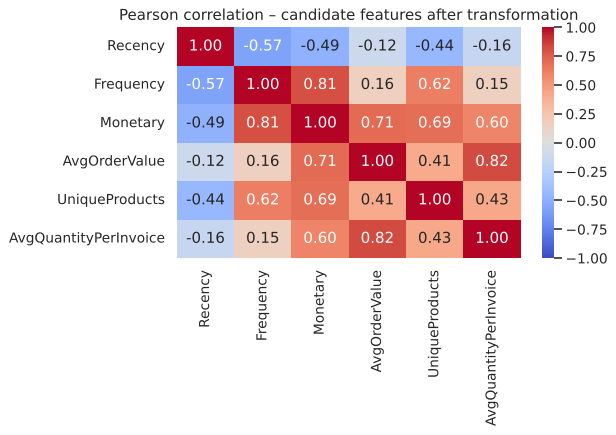

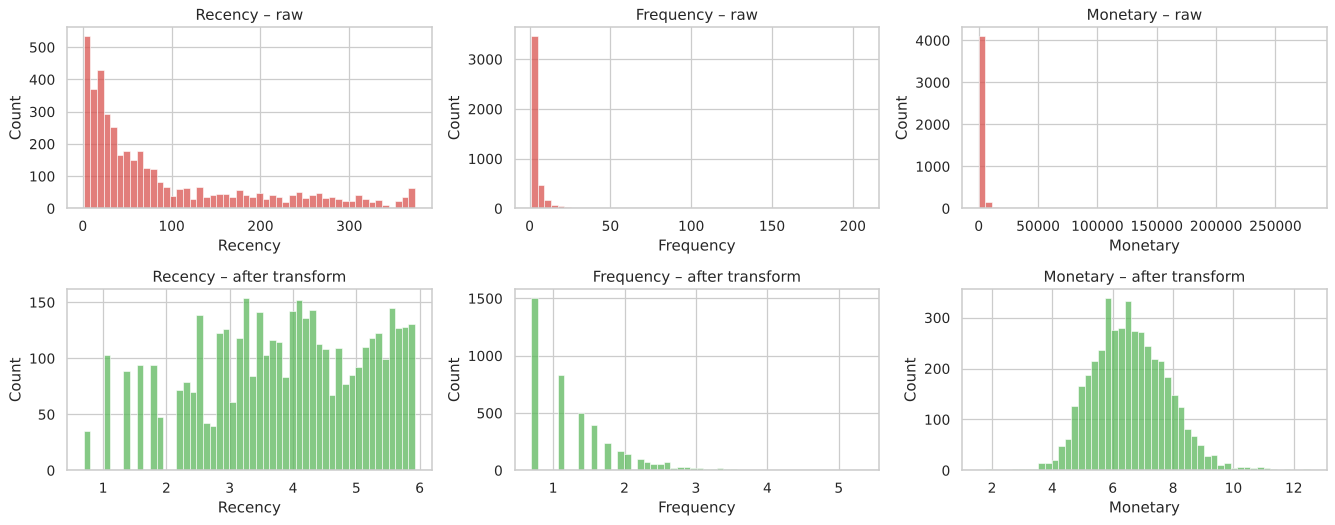

segmentation_scaled: (4334, 6) | missing: 0


,mean,std,min,max
Recency,-0.00,1.00,-2.42,1.58
Frequency,0.00,1.00,-0.95,5.85
Monetary,0.00,1.00,-4.00,4.75
AvgOrderValue,-0.00,1.00,-5.49,7.67
UniqueProducts,-0.00,1.00,-2.52,3.48
AvgQuantityPerInvoice,-0.00,1.00,-4.85,6.87


In [ ]:
core = ["Recency", "Frequency", "Monetary"]
candidates = core + ["AvgOrderValue", "UniqueProducts", "AvgQuantityPerInvoice"]
feat_raw = customer_features.set_index("CustomerID")[candidates].copy()
assert feat_raw.notna().all().all()

skew_before = feat_raw.skew()
feat_t = feat_raw.copy()
log_cols = [c for c in candidates if skew_before[c] > SKEW_THRESHOLD]
for c in log_cols:
    feat_t[c] = np.log1p(feat_raw[c])
skew_after = feat_t.skew()
display(pd.DataFrame({"skew_raw": skew_before, "log1p_applied": [c in log_cols for c in candidates], "skew_after": skew_after}))

# ---- انتخاب ویژگی با کنترل همبستگی ----
corr_t = feat_t.corr(method="pearson")
selected = core.copy()
dropped = []
for c in candidates[len(core):]:
    worst = max(abs(corr_t.loc[c, s]) for s in selected)
    (selected if worst < CORR_DROP_THRESHOLD else dropped).append(c)
display(corr_t.round(2))
print("Selected features:", selected)
print("Dropped (redundant):", dropped)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_t, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation – candidate features after transformation")
plt.tight_layout(); plt.show()

# ---- مقایسه قبل/بعد برای RFM ----
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for j, c in enumerate(core):
    sns.histplot(feat_raw[c], bins=50, ax=axes[0, j], color="#d9534f"); axes[0, j].set_title(f"{c} – raw")
    sns.histplot(feat_t[c], bins=50, ax=axes[1, j], color="#5cb85c"); axes[1, j].set_title(f"{c} – after transform")
plt.tight_layout(); plt.show()

# ---- Scaling ----
segmentation_features = feat_raw[selected].copy()                    # مقادیر واقعی برای تفسیر خوشه‌ها
segmentation_transformed = feat_t[selected].copy()
scaler = StandardScaler().fit(segmentation_transformed)
segmentation_scaled = pd.DataFrame(scaler.transform(segmentation_transformed), index=segmentation_transformed.index,
                                   columns=selected)
scaler_params = {"features": selected, "log1p_applied": [c for c in selected if c in log_cols],
                 "mean": dict(zip(selected, scaler.mean_.round(6))), "scale": dict(zip(selected, scaler.scale_.round(6)))}

print("segmentation_scaled:", segmentation_scaled.shape, "| missing:", int(segmentation_scaled.isna().sum().sum()))
display(segmentation_scaled.describe().T[["mean", "std", "min", "max"]])

facts["seg_selected"] = ", ".join(selected)
facts["seg_dropped"] = ", ".join(dropped) if dropped else "هیچ‌کدام (همه همبستگی‌ها زیر آستانه بودند)"
facts["seg_corr_aov_qty"] = float(corr_t.loc["AvgOrderValue", "AvgQuantityPerInvoice"])
facts["seg_corr_max_nonself"] = float(corr_t.where(~np.eye(len(corr_t), dtype=bool)).abs().max().max())
facts["seg_logged"] = ", ".join(log_cols)
facts["seg_skew_m_before"] = float(skew_before["Monetary"]); facts["seg_skew_m_after"] = float(skew_after["Monetary"])
facts["seg_skew_f_before"] = float(skew_before["Frequency"]); facts["seg_skew_f_after"] = float(skew_after["Frequency"])
facts["seg_skew_r_before"] = float(skew_before["Recency"]); facts["seg_skew_r_after"] = float(skew_after["Recency"])
facts["seg_corr_fm"] = float(corr_t.loc["Frequency", "Monetary"])
facts["seg_n"] = len(segmentation_scaled)
log_flow("8", "segmentation_scaled (customers)", len(segmentation_scaled))

### نتیجه مرحله 8

- ویژگی‌های انتخاب‌شده برای خوشه‌بندی: **Recency, Frequency, Monetary, AvgOrderValue, UniqueProducts, AvgQuantityPerInvoice**. ویژگی‌های حذف‌شده به‌دلیل همبستگی زیاد: **هیچ‌کدام (همه همبستگی‌ها زیر آستانه بودند)**.
- `log1p` روی **Recency, Frequency, Monetary, AvgOrderValue, UniqueProducts, AvgQuantityPerInvoice** اعمال شد. چولگی Monetary از **19.6** به **0.40**، Frequency از **11.9** به **1.21** و Recency از **1.24** به **-0.33** رسید؛ یعنی اثر مشتریان بسیار بزرگ روی فاصله‌ها کنترل شد بدون اینکه حذف شوند.
- بیشترین همبستگی میان ویژگی‌ها **0.82** است (Frequency–Monetary حدود **0.81** و AvgOrderValue–AvgQuantityPerInvoice حدود **0.82**)؛ هر دو زیر آستانه ۰٫۸۵ هستند، پس ویژگی‌ای حذف نشد. اگر در Modeling دیدید این دو جفت روی خوشه‌ها وزن اضافه می‌گذارند، با کاهش `CORR_DROP_THRESHOLD` به ۰٫۸ می‌توان یکی از هر جفت را کنار گذاشت. ویژگی‌های RFM به‌هر حال حفظ می‌شوند.
- چولگی Frequency پس از log هنوز حدود **1.21** است؛ علتش تعداد زیاد مشتریان تک‌فاکتوری است و با تبدیل ساده قابل رفع نیست. Scaling این اثر را کنترل می‌کند.
- `segmentation_scaled` برای **4,334 مشتری**، بدون مقدار گمشده و با میانگین ≈ 0 و انحراف معیار ≈ 1 ساخته شد. نسخه خام در `segmentation_features` و پارامترهای Scaling در `scaler_params.json` ذخیره می‌شود تا برگرداندن به مقیاس اصلی ممکن باشد.

---
# مرحله 9: آماده‌سازی داده برای ارزیابی اقتصادی و انتخاب ۵۰۰ مشتری

**هدف:** ساخت شاخص‌هایی که مشتریان را هم از نظر **ارزش اقتصادی** و هم از نظر **ظرفیت بازاریابی** قابل مقایسه کند. انتخاب ۵۰۰ مشتری نباید فقط بر پایه بیشترین Monetary باشد؛ مشتری پرارزشی که مدتی است نخریده یا خریدش کاملاً لغو شده با مشتری فعال و رو به رشد فرق دارد.

شاخص‌های این مرحله:

| گروه | شاخص |
|---|---|
| ارزش | Monetary، **NetMonetary**، AvgOrderValue، Frequency |
| تازگی و استمرار | Recency، PurchasedInLast90Days، ActiveMonths، ActiveMonthsRatio، AvgInterpurchaseDays |
| روند | Spend_L90 (۹۰ روز اخیر)، Spend_P90 (۹۰ روز قبل از آن)، **SpendGrowthIndex** = (L−P)/(L+P) بین ۱- و ۱ — فقط برای مشتریانی که حداقل ۱۸۰ روز سابقه دارند، وگرنه `NaN` |
| تنوع | UniqueProducts، AvgDistinctProductsPerInvoice |
| ریسک مرجوعی | MatchedReturnRatio، IsFullyReversed |
| رتبه (صدک) | Monetary_Pctl، NetMonetary_Pctl، Frequency_Pctl، AvgOrderValue_Pctl، Recency_Pctl (بالاتر = جدیدتر) |
| کنترل | پرچم‌های پرت، IsUK |

> منطق نهایی امتیازدهی و انتخاب ۵۰۰ مشتری در مرحله تحلیل/ارزیابی اقتصادی تعریف می‌شود؛ اینجا فقط داده تصمیم‌گیری آماده می‌شود.

In [ ]:
cf = customer_features.set_index("CustomerID")
ref = REFERENCE_DATE
w = pd.Timedelta(days=TREND_WINDOW_DAYS)

recent = vct[(vct["InvoiceDate"] >= ref - w) & (vct["InvoiceDate"] < ref)]
prior = vct[(vct["InvoiceDate"] >= ref - 2 * w) & (vct["InvoiceDate"] < ref - w)]

eco = pd.DataFrame(index=cf.index)
eco["Country"], eco["IsUK"] = cf["Country"], cf["IsUK"]
for c in ["Recency", "Frequency", "Monetary", "NetMonetary", "AvgOrderValue", "UniqueProducts",
          "AvgDistinctProductsPerInvoice", "PurchaseDays", "ActiveMonths", "AvgInterpurchaseDays",
          "MatchedReturnRatio", "IsFullyReversed", "CancelledInvoices"]:
    eco[c] = cf[c]

# ---- تداوم فعالیت ----
last_period_idx = ref - pd.Timedelta(days=1)
months_available = ((last_period_idx.year - cf["FirstPurchase"].dt.year) * 12
                    + (last_period_idx.month - cf["FirstPurchase"].dt.month) + 1)
eco["MonthsAvailable"] = months_available
eco["ActiveMonthsRatio"] = (cf["ActiveMonths"] / months_available).clip(upper=1)
eco["PurchasedInLast90Days"] = cf["Recency"] <= TREND_WINDOW_DAYS

# ---- روند خرید ----
eco["Spend_L90"] = recent.groupby("CustomerID")["LineAmount"].sum().reindex(eco.index).fillna(0)
eco["Spend_P90"] = prior.groupby("CustomerID")["LineAmount"].sum().reindex(eco.index).fillna(0)
eligible_trend = cf["FirstPurchase"] <= ref - 2 * w
den = eco["Spend_L90"] + eco["Spend_P90"]
eco["SpendGrowthIndex"] = np.where(eligible_trend & (den > 0), (eco["Spend_L90"] - eco["Spend_P90"]) / den.replace(0, np.nan), np.nan)
eco["TrendEligible"] = eligible_trend

# ---- صدک‌ها (آماده‌سازی رتبه‌بندی، نه امتیاز نهایی) ----
eco["Monetary_Pctl"] = eco["Monetary"].rank(pct=True)
eco["NetMonetary_Pctl"] = eco["NetMonetary"].rank(pct=True)
eco["Frequency_Pctl"] = eco["Frequency"].rank(pct=True)
eco["AvgOrderValue_Pctl"] = eco["AvgOrderValue"].rank(pct=True)
eco["Recency_Pctl"] = 1 - eco["Recency"].rank(pct=True) + 1 / len(eco)    # بالاتر = خرید جدیدتر

# ---- پرچم‌ها ----
for c in ["IsOutlierCustomer", "IsExtremeOutlierCustomer"]:
    eco[c] = cf[c]
eco["HasPositiveNetValue"] = eco["NetMonetary"] > 0

customer_economic_features = eco.reset_index()
display(customer_economic_features[["Recency", "Monetary", "NetMonetary", "ActiveMonthsRatio", "Spend_L90", "Spend_P90",
                                    "SpendGrowthIndex", "MatchedReturnRatio"]].describe().T)
print("Missing values (documented, by design):")
display(customer_economic_features.isna().sum()[lambda s: s > 0].to_frame("missing"))

facts["eco_n"] = len(customer_economic_features)
facts["eco_active90"] = int(eco["PurchasedInLast90Days"].sum())
facts["eco_trend_eligible"] = int(eligible_trend.sum())
facts["eco_growth_defined"] = int(eco["SpendGrowthIndex"].notna().sum())
facts["eco_growth_pos"] = int((eco["SpendGrowthIndex"] > 0).sum())
facts["eco_zero_net"] = int((~eco["HasPositiveNetValue"]).sum())
facts["eco_net_vs_gross_pct"] = float(eco["NetMonetary"].sum() / eco["Monetary"].sum() * 100)
facts["eco_high_value_inactive"] = int(((eco["Monetary_Pctl"] >= 0.9) & (~eco["PurchasedInLast90Days"])).sum())
facts["eco_top10pct_n"] = int((eco["Monetary_Pctl"] >= 0.9).sum())
log_flow("9", "customer_economic_features (customers)", len(customer_economic_features))

,count,mean,std,min,25%,50%,75%,max
Recency,"4,334.00",93.23,100.18,1.00,18.00,51.00,143.00,374.00
Monetary,"4,334.00","2,015.70","8,903.66",3.75,304.24,661.42,"1,631.62","279,138.02"
NetMonetary,"4,334.00","1,912.44","8,297.24",0.00,298.13,649.44,"1,606.41","278,778.02"
ActiveMonthsRatio,"4,334.00",0.37,0.24,0.08,0.18,0.33,0.50,1.00
Spend_L90,"4,334.00",779.20,"4,381.89",0.00,0.00,250.55,679.05,"168,469.60"
Spend_P90,"4,334.00",419.21,"2,133.63",0.00,0.00,0.00,345.20,"62,151.70"
SpendGrowthIndex,"1,956.00",0.22,0.70,-1.00,-0.21,0.29,1.00,1.00
MatchedReturnRatio,"4,334.00",0.02,0.07,0.00,0.00,0.00,0.01,1.00


Missing values (documented, by design):


,missing
AvgInterpurchaseDays,1558
SpendGrowthIndex,2378


### نتیجه مرحله 9

- `customer_economic_features` برای **4,334 مشتری** ساخته شد. **2,885 مشتری** در ۹۰ روز آخر خرید داشته‌اند.
- شاخص روند فقط برای **2,819 مشتری** با سابقه حداقل ۱۸۰ روز قابل تعریف است و عملاً برای **1,956 نفر** مقدار دارد؛ از این تعداد **1,281 مشتری** روند مثبت (رشد خرید اخیر نسبت به دوره قبل) دارند. بقیه عمداً `NaN` هستند، نه صفر.
- **NetMonetary** مجموعاً حدود **94.9٪** از Monetary ناخالص است و **9 مشتری** ارزش خالص صفر دارند (خرید آن‌ها کاملاً برگشته)؛ در انتخاب ۵۰۰ مشتری باید این گروه را مدیریت کرد.
- از **433 مشتری** در دهک بالای Monetary، **22 نفر** در ۹۰ روز آخر خریدی نداشته‌اند؛ دقیقاً همان گروهی که انتخاب صرفاً بر پایه Monetary آن‌ها را بالا می‌برد ولی تازگی ندارند.
- صدک‌ها فقط **داده رتبه‌بندی** هستند و وزن‌دهی نهایی در مرحله بعد تعیین می‌شود.

---
# مرحله 10: اعتبارسنجی نهایی و ذخیره خروجی‌ها (Final Validation & Export)

**هدف:** اطمینان از اینکه خطاهای پاک‌سازی وارد خوشه‌بندی یا استخراج قواعد نمی‌شوند. هر کنترل به‌صورت `PASS/FAIL` ثبت می‌شود و اگر کنترلی `FAIL` شود، ذخیره‌سازی متوقف می‌شود.

In [ ]:
checks = []
def check(name, condition, detail=""):
    checks.append({"Check": name, "Result": "PASS" if bool(condition) else "FAIL", "Detail": detail})

# --- یکپارچگی داده خام و تعداد ردیف‌ها ---
check("Raw data unchanged (raw_df equals working copy retail_df)", raw_df.equals(retail_df))
check("Row reconciliation: raw = cleaned + duplicates_removed", len(raw_df) == len(retail_cleaned) + len(duplicates_removed),
      f"{len(raw_df):,} = {len(retail_cleaned):,} + {len(duplicates_removed):,}")
check("Every cleaned row has exactly one transaction type",
      len(valid_purchases) + len(returns_cancellations) + len(excluded_other_rows) == len(retail_cleaned))

# --- شمارش‌های اصلی ---
n_cust = vct["CustomerID"].nunique()
check("Customer counts consistent across datasets",
      n_cust == len(customer_features) == len(segmentation_scaled) == len(customer_economic_features), f"{n_cust:,} customers")
check("Valid invoice count consistent", valid_product_transactions["InvoiceNo"].nunique() == len(invoice_summary),
      f"{len(invoice_summary):,} invoices")
check("Customer invoices are a subset of valid invoices", set(vct["InvoiceNo"]) <= set(valid_product_transactions["InvoiceNo"]))
check("ARM baskets are a subset of valid invoices", set(basket_matrix.index) <= set(valid_product_transactions["InvoiceNo"]),
      f"{len(basket_matrix):,} baskets / {basket_matrix.shape[1]:,} items")

# --- یکتایی کلیدها ---
check("CustomerID unique in customer_features", customer_features["CustomerID"].is_unique)
check("CustomerID unique in customer_economic_features", customer_economic_features["CustomerID"].is_unique)
check("InvoiceNo unique in invoice_summary", invoice_summary["InvoiceNo"].is_unique)
check("InvoiceNo unique in basket_matrix / basket_data", basket_matrix.index.is_unique and basket_data["InvoiceNo"].is_unique)
check("StockCode unique in product_catalog", product_catalog["StockCode"].is_unique)

# --- سازگاری مالی ---
check("Sum of Monetary equals valid customer purchase value",
      np.isclose(customer_features["Monetary"].sum(), vct["LineAmount"].sum()),
      f"{customer_features['Monetary'].sum():,.2f} GBP")
check("Sum of invoice values equals valid product purchase value",
      np.isclose(invoice_summary["InvoiceValue"].sum(), valid_product_transactions["LineAmount"].sum()))
check("NetMonetary never exceeds Monetary and never negative",
      ((customer_features["NetMonetary"] <= customer_features["Monetary"] + 1e-9) & (customer_features["NetMonetary"] >= 0)).all())

# --- قواعد خرید معتبر ---
check("Valid purchases: Quantity > 0 and UnitPrice > 0", ((valid_product_transactions["Quantity"] > 0) & (valid_product_transactions["UnitPrice"] > 0)).all())
check("Valid purchases contain no cancellation invoices (C*)", not valid_product_transactions["InvoiceNo"].str.startswith("C").any())
check("Valid purchases contain no non-product codes", not valid_product_transactions["IsNonProduct"].any())
check("Customer transactions all have CustomerID", valid_customer_transactions["CustomerID"].notna().all())
nonprod_codes_seen = set(retail_cleaned.loc[retail_cleaned["IsNonProduct"], "StockCode"])
check("Basket matrix columns contain no non-product code", not (set(basket_matrix.columns) & nonprod_codes_seen))

# --- ماتریس سبد ---
check("Basket matrix contains only 0/1", set(np.unique(basket_matrix.values)) <= {0, 1})
check("Basket matrix: every column has Support >= MIN_ITEM_SUPPORT_FOR_MATRIX",
      (basket_matrix.mean() >= MIN_ITEM_SUPPORT_FOR_MATRIX - 1e-12).all())

# --- ویژگی‌های نهایی ---
check("No missing values in R, F, M, AvgOrderValue", customer_features[["Recency", "Frequency", "Monetary", "AvgOrderValue"]].notna().all().all())
allowed_nan = {"AvgInterpurchaseDays"}
nan_cols = set(customer_features.columns[customer_features.isna().any()])
check("Missing values in customer_features only where documented", nan_cols <= allowed_nan, f"columns with NaN: {sorted(nan_cols)}")
check("Recency >= 1 for all customers", (customer_features["Recency"] >= 1).all())
check("Frequency >= 1 and Monetary > 0", ((customer_features["Frequency"] >= 1) & (customer_features["Monetary"] > 0)).all())
check("Segmentation matrix has no missing values", not segmentation_scaled.isna().any().any())
check("Segmentation matrix is standardized (mean≈0, std≈1)",
      np.allclose(segmentation_scaled.mean(), 0, atol=1e-6) and np.allclose(segmentation_scaled.std(), 1, atol=1e-2))
check("Segmentation customers match customer_features", set(segmentation_scaled.index) == set(customer_features["CustomerID"]))
check("SpendGrowthIndex within [-1, 1]", customer_economic_features["SpendGrowthIndex"].dropna().between(-1, 1).all())

validation_checks = pd.DataFrame(checks)
display(validation_checks)
n_fail = int((validation_checks["Result"] == "FAIL").sum())
facts["n_checks"], facts["n_fail"] = len(validation_checks), n_fail
assert n_fail == 0, "برخی کنترل‌ها FAIL شده‌اند؛ پیش از ذخیره‌سازی باید بررسی شوند."
print(f"All {len(validation_checks)} checks passed.")

,Check,Result,Detail
0,Raw data unchanged (raw_df equals working copy...,PASS,
1,Row reconciliation: raw = cleaned + duplicates...,PASS,"541,909 = 536,641 + 5,268"
2,Every cleaned row has exactly one transaction ...,PASS,
3,Customer counts consistent across datasets,PASS,"4,334 customers"
4,Valid invoice count consistent,PASS,"19,773 invoices"
5,Customer invoices are a subset of valid invoices,PASS,
6,ARM baskets are a subset of valid invoices,PASS,"18,267 baskets / 1,612 items"
7,CustomerID unique in customer_features,PASS,
8,CustomerID unique in customer_economic_features,PASS,
9,InvoiceNo unique in invoice_summary,PASS,


All 30 checks passed.


In [ ]:
# ---------------- ثبت تصمیم‌ها و جریان رکوردها ----------------
decision_log = pd.DataFrame([
    ["Raw data", "Never modified; all work on retail_df/retail_cleaned", "Traceability"],
    ["CustomerID missing", f"{facts['miss_customer']:,} rows kept in retail_cleaned; no fake IDs; excluded from customer analyses, kept for ARM", "Needed for customer-level only"],
    ["Exact duplicates", f"{facts['dup_rows']:,} rows removed (saved in duplicates_removed); no invoice or invoice-product pair lost", "Prevents inflated Quantity/Monetary"],
    ["Cancellations (C*)", "Separated into returns_cancellations; matched to prior customer-product purchases", "Cancellation ≠ return; kept for return indices"],
    ["Negative Qty without C", "Treated as inventory adjustment; excluded from sales and baskets", "Zero price, no CustomerID, notes like check/damaged"],
    ["Non-product codes", "POST, DOT, M, D, C2, S, B, BANK CHARGES, AMAZONFEE, CRUK, GIFT_* excluded from Monetary and baskets", "Fees/services, not sellable products"],
    ["Zero / negative price", "Excluded from valid purchases; kept in excluded_other_rows", "Not a real sale"],
    ["Outliers", "Flagged (IQR 1.5× and 3×), not removed; log1p + scaling only in segmentation copy", "Wholesale customers may be most valuable"],
    ["RFM", f"Single fixed reference date {facts['ref_date']} (last valid purchase + 1 day); Frequency = valid invoices", "Roadmap definition"],
    ["Interpurchase / Trend", "NaN when history is insufficient (<2 purchase days / <180 days)", "No fabricated values"],
    ["ARM baskets", "Unique StockCode per valid invoice; single-item baskets dropped; items with Support ≥ 0.5% in matrix", "Rules need ≥2 items; keeps matrix tractable"],
    ["Segmentation features", f"Selected: {facts['seg_selected']}; log1p on skewed; StandardScaler", "Distance-based algorithms are scale-sensitive"],
], columns=["Topic", "Decision", "Reason"])
display(decision_log)

data_preparation_flow = pd.DataFrame(flow_log)
display(data_preparation_flow)

,Topic,Decision,Reason
0,Raw data,Never modified; all work on retail_df/retail_c...,Traceability
1,CustomerID missing,"135,080 rows kept in retail_cleaned; no fake I...",Needed for customer-level only
2,Exact duplicates,"5,268 rows removed (saved in duplicates_remove...",Prevents inflated Quantity/Monetary
3,Cancellations (C*),Separated into returns_cancellations; matched ...,Cancellation ≠ return; kept for return indices
4,Negative Qty without C,Treated as inventory adjustment; excluded from...,"Zero price, no CustomerID, notes like check/da..."
5,Non-product codes,"POST, DOT, M, D, C2, S, B, BANK CHARGES, AMAZO...","Fees/services, not sellable products"
6,Zero / negative price,Excluded from valid purchases; kept in exclude...,Not a real sale
7,Outliers,"Flagged (IQR 1.5× and 3×), not removed; log1p ...",Wholesale customers may be most valuable
8,RFM,Single fixed reference date 2011-12-10 (last v...,Roadmap definition
9,Interpurchase / Trend,NaN when history is insufficient (<2 purchase ...,No fabricated values


,Step,Description,Rows
0,1,Raw rows (working copy),541909
1,2,Exact duplicate rows removed (saved in duplica...,5268
2,2,retail_cleaned rows,536641
3,3,valid_purchases (valid product purchase rows),522461
4,3,returns_cancellations,10586
5,3,"excluded_other_rows (non-product, zero/negativ...",3594
6,5,valid_product_transactions,522461
7,5,valid_customer_transactions,391074
8,6,customer_features (customers),4334
9,7,basket_matrix invoices,18267


In [ ]:
# ---------------- ساخت و ذخیره فقط دو خروجی نهایی ----------------

# 1) دیتاست جامع مشتری: ترکیب ویژگی‌های رفتاری، اقتصادی و نسخه استانداردشده برای Segmentation
cf_export = customer_features.copy()
eco_export = customer_economic_features.copy()
seg_export = segmentation_scaled.copy()

# یکسان‌سازی کلید اتصال؛ CustomerID در هر سه جدول باید یکتا باشد
for _df in (cf_export, eco_export, seg_export):
    if "CustomerID" not in _df.columns:
        _df.reset_index(inplace=True)

assert cf_export["CustomerID"].is_unique
assert eco_export["CustomerID"].is_unique
assert seg_export["CustomerID"].is_unique

# اطلاعات اقتصادی مبنای ستون‌های مشترک است؛ ویژگی‌های رفتاریِ تکمیلی نیز از customer_features اضافه می‌شوند
customer_analysis = eco_export.merge(
    cf_export, on="CustomerID", how="left", suffixes=("", "_behavior"), validate="one_to_one"
)

# افزودن ویژگی‌های استانداردشده با پیشوند Seg_ تا با مقادیر خام تداخل نداشته باشند
seg_columns = [c for c in seg_export.columns if c != "CustomerID"]
seg_export = seg_export.rename(columns={c: f"Seg_{c}" for c in seg_columns})
customer_analysis = customer_analysis.merge(
    seg_export, on="CustomerID", how="left", validate="one_to_one"
)
customer_analysis = customer_analysis.sort_values("CustomerID").reset_index(drop=True)

# 2) ماتریس سبد خرید؛ index فاکتور به‌صورت ستون InvoiceNo ذخیره می‌شود
product_basket = basket_matrix.copy()
product_basket.index.name = "InvoiceNo"
product_basket = product_basket.reset_index()

# کنترل‌های نهایی مربوط به دو فایل خروجی
assert customer_analysis["CustomerID"].is_unique
assert len(customer_analysis) == customer_features["CustomerID"].nunique()
assert product_basket["InvoiceNo"].is_unique
assert set(np.unique(product_basket.drop(columns="InvoiceNo").to_numpy())) <= {0, 1}

customer_path = os.path.join(OUTPUT_DIR, "customer_analysis.csv")
basket_path = os.path.join(OUTPUT_DIR, "product_basket.csv.gz")
customer_analysis.to_csv(customer_path, index=False)
product_basket.to_csv(basket_path, index=False, compression="gzip")

final_manifest = pd.DataFrame([
    {"Dataset": "customer_analysis", "Rows": len(customer_analysis), "Columns": customer_analysis.shape[1],
     "File": os.path.basename(customer_path), "Size_MB": os.path.getsize(customer_path) / 1024**2,
     "Purpose": "Customer segmentation, economic value, marketing opportunity, top-500 selection"},
    {"Dataset": "product_basket", "Rows": len(product_basket), "Columns": product_basket.shape[1],
     "File": os.path.basename(basket_path), "Size_MB": os.path.getsize(basket_path) / 1024**2,
     "Purpose": "Association Rule Mining"},
])

display(final_manifest)
print("Exactly two final datasets saved in:", os.path.abspath(OUTPUT_DIR))
print("Customer dataset:", customer_path)
print("Product basket:", basket_path)

# پارامترهای تبدیل/Scaling برای بازتولیدپذیری نگه داشته می‌شوند (فایل دیتاست سوم محسوب نمی‌شوند)
with open(os.path.join(OUTPUT_DIR, "scaler_params.json"), "w", encoding="utf-8") as f:
    json.dump({**scaler_params, "reference_date": str(REFERENCE_DATE.date())}, f, ensure_ascii=False, indent=2, default=float)

,Dataset,Rows,Columns,File,Size_MB
0,retail_cleaned,536641,13,retail_cleaned.csv,69.41
1,valid_customer_transactions,391074,21,valid_customer_transactions.csv,69.01
2,valid_product_transactions,522461,21,valid_product_transactions.csv,91.28
3,returns_cancellations,10586,18,returns_cancellations.csv,1.78
4,excluded_other_rows,3594,13,excluded_other_rows.csv,0.37
5,duplicates_removed,5268,10,duplicates_removed.csv,0.51
6,invoice_summary,19773,9,invoice_summary.csv,1.39
7,customer_features,4334,34,customer_features.csv,0.94
8,basket_data,18267,6,basket_data.csv,3.90
9,basket_matrix,18267,1613,basket_matrix.csv.gz,0.72


Parquet written: False | Output folder: /home/claude/data/prepared_data


---
# جمع‌بندی مرحله Data Preparation

در این نسخه، تمام مراحل پاک‌سازی، تفکیک خرید معتبر، مدیریت لغو/مرجوعی، ساخت ویژگی‌های مشتری، آماده‌سازی سبد خرید و کنترل کیفیت بدون تغییر در منطق تحلیلی اجرا می‌شوند؛ اما خروجی‌های قابل استفاده در مراحل بعد در **دو دیتاست نهایی** تجمیع می‌شوند.

| فایل نهایی | محتوای اصلی | کاربرد |
|---|---|---|
| `customer_analysis.csv` | ویژگی‌های RFM، رفتاری، اقتصادی و ستون‌های استانداردشده با پیشوند `Seg_` | Customer Segmentation، تحلیل ارزش اقتصادی، فرصت بازاریابی و انتخاب ۵۰۰ مشتری |
| `product_basket.csv.gz` | ماتریس ۰/۱ فاکتور-محصول با ستون `InvoiceNo` | Association Rule Mining |

**نکته:** دیتافریم‌های میانی مانند `valid_customer_transactions`، `returns_cancellations`، `basket_data` و `product_catalog` همچنان داخل نوت‌بوک ساخته می‌شوند و برای محاسبات و اعتبارسنجی لازم‌اند؛ فقط دیگر به‌صورت فایل‌های جداگانه ذخیره نمی‌شوند. فایل `scaler_params.json` نیز صرفاً پارامتر فنی بازتولید Scaling است، نه دیتاست تحلیلی سوم.

**محدودیت‌های تفسیری:** Monetary ناخالص و NetMonetary جداگانه نگهداری می‌شوند؛ تطبیق مرجوعی با خرید قبلی قطعی نیست؛ فاکتورهای بدون CustomerID در ARM قابل استفاده‌اند اما در تحلیل مشتری وارد نمی‌شوند؛ و دسامبر ۲۰۱۱ ناقص است.

**گام بعدی:** Modeling؛ خوشه‌بندی با ستون‌های `Seg_` در `customer_analysis.csv`، تفسیر خوشه‌ها با مقادیر خام همان فایل، استخراج قواعد از `product_basket.csv.gz` و رتبه‌بندی مشتریان از ویژگی‌های اقتصادی همان فایل.